**REDES**

**En este bloque haré:**

haré red general / ofensiva / defensiva

centralidades ponderadas

optimizacion de quintetos

comparacion con los quintetos usados

**siguiente bloque :** conexion con la fisica , interpretacion, utilidad , limitaciones , entropia


imprtar las librerias

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

conecto con drive

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


para comprobar si estan las carpetas dentro del drive

In [3]:
CARPETA_PROYECTO = Path(
    "/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas"
)

CARPETA_PAREJAS = (
    CARPETA_PROYECTO / "Dataset_parejas"
)

CARPETA_QUINTETOS = (
    CARPETA_PROYECTO / "csv_quintetos"
)

print("Carpeta del proyecto:")
print(CARPETA_PROYECTO)

print("\nCarpeta de parejas:")
print(CARPETA_PAREJAS)

print("\nCarpeta de quintetos:")
print(CARPETA_QUINTETOS)


Carpeta del proyecto:
/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas

Carpeta de parejas:
/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Dataset_parejas

Carpeta de quintetos:
/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/csv_quintetos


para ver los 7 csv si estan correctamente los de parejas

In [4]:
archivos_parejas = sorted(
    CARPETA_PAREJAS.glob("*.csv")
)

print(
    "Número de archivos encontrados:",
    len(archivos_parejas)
)

print("\nArchivos de parejas:")

for archivo in archivos_parejas:
    print("-", archivo.name)

Número de archivos encontrados: 7

Archivos de parejas:
- ESP_vs_C_131892.csv
- ESP_vs_E_131878.csv
- ESP_vs_F_131919.csv
- ESP_vs_I_131897.csv
- ESP_vs_M_131881.csv
- ESP_vs_S_131905.csv
- ESP_vs_T_131880.csv


quiero cargar un csv de preuba:

-cojo el primer archivo de la lista

-lo cargo como dataframe

-quiero ver el nombre del partido

-filas y columnas

-ver las columnas

-las 5 parejas primeras

In [5]:
archivo_prueba = archivos_parejas[0]
df_prueba = pd.read_csv(
    archivo_prueba,
    encoding="utf-8-sig"
)

print("Archivo cargado:")
print(archivo_prueba.name)

print("\ndiimensiones:")
print(df_prueba.shape)

print("\ncolumnas:")
print(df_prueba.columns.tolist())

display(df_prueba.head())

Archivo cargado:
ESP_vs_C_131892.csv

diimensiones:
(49, 10)

columnas:
['Jugadora 1', 'Jugadora 2', 'Min', 'PF', 'PC', '+/-', 'Aro/min', 'Media/min', 'Triple/min', 'Finalizaciones PB/min']


,Jugadora 1,Jugadora 2,Min,PF,PC,+/-,Aro/min,Media/min,Triple/min,Finalizaciones PB/min
0,J11,J1,25.4,61,15,46,0.55,1.02,0.0,0.196464
1,J9,J1,21.7,53,11,42,0.55,1.06,0.0,0.184473
2,J11,J9,20.0,48,11,37,0.60,1.00,0.0,0.200334
3,J10,J7,12.6,37,8,29,0.63,1.19,0.0,0.237154
4,J11,J7,16.3,36,11,25,0.55,1.10,0.0,0.244898


Todo ok, tengo que unir los 7 csv en uno solo.

cada csv se carga por separado y lo quiero añadir a la columna partido. Luego con pd.concat() concadeno todos los archivos uno debajo de otro -> tabla unica

In [6]:
#liista donde se guarda cada DataFrame
lista_partidos = []

for archivo in archivos_parejas:

    #leer el CSV
    df_partido = pd.read_csv(
        archivo,
        encoding="utf-8-sig"
    )

    # Guardar el partido del q procede cada fila
    df_partido["Partido"] = archivo.stem

    #añadir ese partido a la lista
    lista_partidos.append(df_partido)

In [7]:
#Uno tods los partidos en 1 dataframe
df_parejas_total = pd.concat(
    lista_partidos,
    ignore_index=True
)

print("dimensiones del dataset unido:")
print(df_parejas_total.shape)

print("\nNumero de partidos:")
print(df_parejas_total["Partido"].nunique())

display(df_parejas_total.head())

dimensiones del dataset unido:
(361, 11)

Numero de partidos:
7


,Jugadora 1,Jugadora 2,Min,PF,PC,+/-,Aro/min,Media/min,Triple/min,Finalizaciones PB/min,Partido
0,J11,J1,25.4,61,15,46,0.55,1.02,0.0,0.196464,ESP_vs_C_131892
1,J9,J1,21.7,53,11,42,0.55,1.06,0.0,0.184473,ESP_vs_C_131892
2,J11,J9,20.0,48,11,37,0.60,1.00,0.0,0.200334,ESP_vs_C_131892
3,J10,J7,12.6,37,8,29,0.63,1.19,0.0,0.237154,ESP_vs_C_131892
4,J11,J7,16.3,36,11,25,0.55,1.10,0.0,0.244898,ESP_vs_C_131892


ahora tengo que preparar el nombre de las columnas  y ordenar las parejas

porque si me aparecen las parejas como j1-j11 y j11-j1 las dos me van a aparecer luego como j1-j11 ya ordenadas

In [8]:
# Creo 1 copia para trabajar sin modificar la tablaoriginal
df_red = df_parejas_total.copy()
#Simplificar los nombres columnas
df_red = df_red.rename(columns={
    "Jugadora 1": "Jugadora_1",
    "Jugadora 2": "Jugadora_2",
    "+/-": "Plus_Minus",
    "Aro/min": "Aro_Min",
    "Media/min": "Media_Min",
    "Triple/min": "Triple_Min",
    "Finalizaciones PB/min": "PB_Min"
})

ahora viene lo del ordenamiento de las jugadoras, ojo! Jxx-xx

In [9]:
# Extraer el num del jugador: Jxx-xx
def numero_jugadora(codigo):

    return int(
        str(codigo).replace("J", "")
    )

#colocar primero el jugador cn el num menor
parejas_ordenadas = df_red.apply(
    lambda fila: sorted(
        [
            fila["Jugadora_1"],
            fila["Jugadora_2"]
        ],
        key=numero_jugadora
    ),
    axis=1,
    result_type="expand"
)

df_red[["Jugadora_1", "Jugadora_2"]] = parejas_ordenadas

no cambio quien jugó con quien sino que hago un orden. Me queda la comprobacion para veer si hay parejas repetidas

In [10]:
print("columnas preparadas:")
print(df_red.columns.tolist())

print("\nparejas repetidas del mismo partido:")
print(
    df_red.duplicated(
        subset=[
            "Partido",
            "Jugadora_1",
            "Jugadora_2"
        ]
    ).sum()
)

display(
    df_red[
        [
            "Jugadora_1",
            "Jugadora_2",
            "Min",
            "PF",
            "PC",
            "Plus_Minus",
            "Partido"
        ]
    ].head()
)

columnas preparadas:
['Jugadora_1', 'Jugadora_2', 'Min', 'PF', 'PC', 'Plus_Minus', 'Aro_Min', 'Media_Min', 'Triple_Min', 'PB_Min', 'Partido']

parejas repetidas del mismo partido:
0


,Jugadora_1,Jugadora_2,Min,PF,PC,Plus_Minus,Partido
0,J1,J11,25.4,61,15,46,ESP_vs_C_131892
1,J1,J9,21.7,53,11,42,ESP_vs_C_131892
2,J9,J11,20.0,48,11,37,ESP_vs_C_131892
3,J7,J10,12.6,37,8,29,ESP_vs_C_131892
4,J7,J11,16.3,36,11,25,ESP_vs_C_131892


en los csv tengo tasas por min -> antes de unir los partidos -> recuperar aprox los recuentos originales  

Aro= (aro /min) x minutos

-Valores aprox porque los csv ya estan redondeados

En cada csv no tengo el num original de llegadas sino la tasa : aro/min= llegadas aro/ minutos compartidos

si tuvieese min=25,4 y aro/min=0,55 -> aro= 0,55x25,4=13,97 llegadas -> 14 llegadas

IMPORTANTE!!!! lo hago porque no seria correcto calcular la media sencilla de las tasas de los dos partidos -> daria la misma importancia a un partido de 2 min que a otro de 15 por ejemplo

tengo que:

multiplicar cda tasa por sus minutos para recuperar el total del partido, luego sumar esos totaltes entre los 7 partidos -> los sumo (minutos) -> divido el total de acciones entre los minutos acumulados.

In [11]:
# Recuperar los totales aproximados de cada zona
df_red["Aro"] = (
    df_red["Aro_Min"] * df_red["Min"]
)

df_red["Media"] = (
    df_red["Media_Min"] * df_red["Min"]
)

df_red["Triple"] = (
    df_red["Triple_Min"] * df_red["Min"]
)

df_red["PB"] = (
    df_red["PB_Min"] * df_red["Min"]
)

ahora agurpo los 7 partidos

In [12]:
df_parejas_red = (
    df_red
    .groupby(
        ["Jugadora_1", "Jugadora_2"],
        as_index=False
    )
    .agg(
        Min=("Min", "sum"),
        PF=("PF", "sum"),
        PC=("PC", "sum"),
        Aro=("Aro", "sum"),
        Media=("Media", "sum"),
        Triple=("Triple", "sum"),
        PB=("PB", "sum"),
        Partidos=("Partido", "nunique")
    )
)

Tengo que usar los totales para volver a calcular todas las metricas

In [13]:
# Diferencial acumulado
df_parejas_red["Plus_Minus"] = (
    df_parejas_red["PF"] -
    df_parejas_red["PC"]
)

los puntos anotados por españa cada min compartido x pareja -> clave para la red ofensiva

In [14]:
# Producción por minuto acumulada
df_parejas_red["PF_Min"] = (
    df_parejas_red["PF"] /
    df_parejas_red["Min"]
)

puntos recibidos (encontra) por españa por cada min compartido x la pareja -> clave para la red defensiva

In [15]:
df_parejas_red["PC_Min"] = (
    df_parejas_red["PC"] /
    df_parejas_red["Min"]
)

a partir de aqui los puedo usar para describir el perfil ofensivo o para mejorar la optimizacion

llegadas / acciones de media distancia x min compartido

In [16]:
df_parejas_red["Aro_Min"] = (
    df_parejas_red["Aro"] /
    df_parejas_red["Min"]
)

acciones desde media distancia x min compartido

In [17]:
df_parejas_red["Media_Min"] = (
    df_parejas_red["Media"] /
    df_parejas_red["Min"]
)

acciones desde la zona triple x min compartido

In [18]:
df_parejas_red["Triple_Min"] = (
    df_parejas_red["Triple"] /
    df_parejas_red["Min"]
)

finalizaciones desde el POSTE BAJO  x min compartido

In [19]:
df_parejas_red["PB_Min"] = (
    df_parejas_red["PB"] /
    df_parejas_red["Min"]
)

COMPROBAR LA TABLA FINAAAL

In [20]:
print(
    "numero de parejas diferentes:",
    len(df_parejas_red)
)
print(
    "numero de jugadoras:",
    len(
        set(df_parejas_red["Jugadora_1"])
        | set(df_parejas_red["Jugadora_2"])
    )
)
print(
    "Minutos-pareja acumulads:",
    round(df_parejas_red["Min"].sum(), 1)
)
display(
    df_parejas_red
    .sort_values("Min", ascending=False)
    .head(10)
)

numero de parejas diferentes: 65
numero de jugadoras: 12
Minutos-pareja acumulads: 2800.7


,Jugadora_1,Jugadora_2,Min,PF,PC,Aro,Media,Triple,PB,Partidos,Plus_Minus,PF_Min,PC_Min,Aro_Min,Media_Min,Triple_Min,PB_Min
9,J1,J9,103.5,199,105,98.050,78.010,2.938,19.016143,7,94,1.922705,1.014493,0.947343,0.753720,0.028386,0.183731
7,J1,J7,102.6,192,113,97.242,74.010,2.062,21.023636,7,79,1.871345,1.101365,0.947778,0.721345,0.020097,0.204909
1,J1,J11,90.0,189,79,99.361,63.004,3.043,19.033790,7,110,2.100000,0.877778,1.104011,0.700044,0.033811,0.211487
57,J7,J9,87.6,169,105,89.930,65.209,3.054,18.003345,7,64,1.929224,1.198630,1.026598,0.744395,0.034863,0.205518
36,J4,J6,86.7,191,78,103.942,70.182,1.032,20.023274,7,113,2.202999,0.899654,1.198870,0.809481,0.011903,0.230949
16,J2,J3,79.1,171,74,80.890,59.856,3.042,16.954659,7,97,2.161820,0.935525,1.022630,0.756713,0.038458,0.214345
0,J1,J10,75.5,141,80,79.085,66.001,1.030,16.992427,7,61,1.867550,1.059603,1.047483,0.874185,0.013642,0.225065
28,J3,J6,74.0,152,58,84.069,59.134,2.022,19.015091,7,94,2.054054,0.783784,1.136068,0.799108,0.027324,0.256961
17,J2,J4,71.1,160,73,73.077,57.170,0.945,18.008269,7,87,2.250352,1.026723,1.027806,0.804079,0.013291,0.253281
63,J9,J11,71.1,150,53,67.064,48.042,3.008,17.011312,7,97,2.109705,0.745429,0.943235,0.675696,0.042307,0.239259


comprobacion de los valores que me pueden dar problemas

quiero tener : 0 valores ausentes, 0 parejas x min = o < 0 ..

In [21]:
columnas_red = [
    "Min",
    "PF",
    "PC",
    "Plus_Minus",
    "PF_Min",
    "PC_Min",
    "Aro_Min",
    "Media_Min",
    "Triple_Min",
    "PB_Min"
]

In [22]:
print("Valores ausentes:")
print(
    df_parejas_red[columnas_red]
    .isna()
    .sum()
)

print(
    "\nParejas con minutos iguales o menores que cero:",
    (df_parejas_red["Min"] <= 0).sum()
)

print(
    "\nParejas con menos de 5 minutos:",
    (df_parejas_red["Min"] < 5).sum()
)

Valores ausentes:
Min           0
PF            0
PC            0
Plus_Minus    0
PF_Min        0
PC_Min        0
Aro_Min       0
Media_Min     0
Triple_Min    0
PB_Min        0
dtype: int64

Parejas con minutos iguales o menores que cero: 0

Parejas con menos de 5 minutos: 0


lo voy a guardar el csv:

tiene -> una unica fila por pareja, min acumulados de los 7 partidos, pf,pc, y el +- acumulados , las metricas ofensivas recalculadas x minuto , num de partidos en los que está esa pareja

In [23]:
CARPETA_REDES = Path(
    "/content/drive/MyDrive/TFG_UGR/Redes_UGR"
)

# Crear la carpeta únicamente si todavía no existe
CARPETA_REDES.mkdir(
    parents=True,
    exist_ok=True
)

In [24]:
ruta_parejas_red = (
    CARPETA_REDES /
    "parejas_consolidadas_redes.csv"
)

df_parejas_red.to_csv(
    ruta_parejas_red,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset consolidado guardado en:")
print(ruta_parejas_red)

Dataset consolidado guardado en:
/content/drive/MyDrive/TFG_UGR/Redes_UGR/parejas_consolidadas_redes.csv


**RED GENERAL**

primero las librerias , networkX es para crear y analizar redes y el plot para dibujar

In [25]:
import networkx as nx
import matplotlib.pyplot as plt

**red no dirigida ->** tengo relacion simetrica , xk si j1 comparte minutos con j2 , j2 tb comparte minutos con j1

**cada jugadora es un nodo**

**cada parejas es un enlace**

**minutos** me guarda la **fuerza de la conexion** IMPORTANTE!!!

In [26]:
# Crear red no dirigida
G_general = nx.Graph()

# Añadir 1 conexión x cada pareja
for _, fila in df_parejas_red.iterrows():

    G_general.add_edge(
        fila["Jugadora_1"],
        fila["Jugadora_2"],
        minutos=float(fila["Min"])
    )

comprobar la estructura

la densidad es alta porque ocn 12 jugadoras la combinatoria (12 2) = 66 parejas posibles -> casi todas las jugadoras han coincidido con las otras

In [27]:
print(
    "Número de nodos:",
    G_general.number_of_nodes()
)

print(
    "Número de enlaces:",
    G_general.number_of_edges()
)

print(
    "Densidad de la red:",
    round(nx.density(G_general), 3)
)

print(
    "Red conectada:",
    nx.is_connected(G_general)
)


Número de nodos: 12
Número de enlaces: 65
Densidad de la red: 0.985
Red conectada: True


**conclusion ->** la centralidad de grado aporta poca informacion xk casi todos los nodos tienen mas o menos el mismo numero de conexiones -> luego me interesara ver la centralidad ponderada x min ¡recordar!

**DIBUJAR**

tengo que preparar la posicion de los NODOS , con spring_layout coloco los jugadores como si los enlaces fuesen muelles

las conexiones con + min tienen + fuerza

las parejas con mayor relacion tienden a aparecer + proximas

seed=42 hace que el grafico conserve la distribucion

con pos guardo las posiciones para tener las mismas posiciones en las redes ofensiva y defensiva

In [28]:
pos = nx.spring_layout(
    G_general,
    weight="minutos",
    seed=42,
    k=1.2
)

tengo que ver el grosor y el color de los enlaces

conexiones con + min -> + gruesas y oscuras

In [29]:
minutos_enlaces = [
    G_general[u][v]["minutos"]
    for u, v in G_general.edges()
]

minutos_maximos = max(minutos_enlaces)

grosores = [
    0.5 + 5 * minutos / minutos_maximos
    for minutos in minutos_enlaces
]

**GRAFICO RED GENERAL**

Cada circulo es un jugador

cada linea es una preja que coincide en pista

si es + gruesa y oscura la linea -> + minutos comparten en pista

posicion no representa la zona de la cancha -> da el equilibrio de fuerzas

como tengo 65/66 conexiones posibles la red será densa OJO!!!  lo importante debe ser el grosor y el color de los enlaces

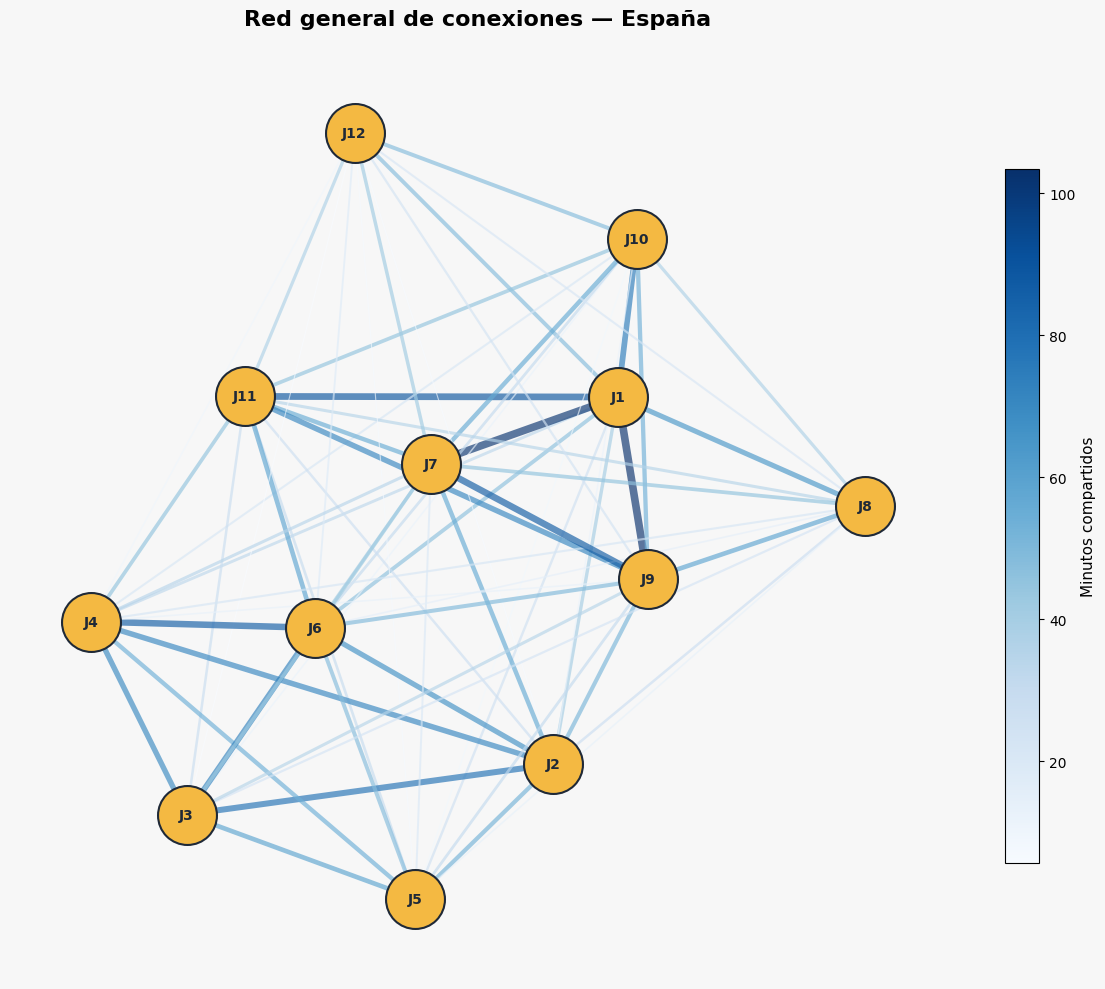

In [30]:
fig, ax = plt.subplots(
    figsize=(12, 10),
    facecolor="#F7F7F7"
)

ax.set_facecolor("#F7F7F7")

# Dibujar enlaces
nx.draw_networkx_edges(
    G_general,
    pos,
    ax=ax,
    edge_color=minutos_enlaces,
    edge_cmap=plt.cm.Blues,
    edge_vmin=min(minutos_enlaces),
    edge_vmax=max(minutos_enlaces),
    width=grosores,
    alpha=0.65
)

# Dibujar nodos
nx.draw_networkx_nodes(
    G_general,
    pos,
    ax=ax,
    node_size=1800,
    node_color="#F4B942",
    edgecolors="#1F2937",
    linewidths=1.5
)

# Añadir etiquetas
nx.draw_networkx_labels(
    G_general,
    pos,
    ax=ax,
    font_size=10,
    font_weight="bold",
    font_color="#1F2937"
)

# Barra d color
mapeo_color = plt.cm.ScalarMappable(
    cmap=plt.cm.Blues,
    norm=plt.Normalize(
        vmin=min(minutos_enlaces),
        vmax=max(minutos_enlaces)
    )
)

mapeo_color.set_array([])

barra = plt.colorbar(
    mapeo_color,
    ax=ax,
    shrink=0.75
)

barra.set_label(
    "Minutos compartidos",
    fontsize=11
)

plt.title(
    "Red general de conexiones — España",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    CARPETA_REDES / "red_general.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

para sabere mejor las conexiones principales mejor tabla

min -> totales compartidos

partidos -> los encuentros en los que aparece la pareja

**RED GENERAL ->** qué parejas tuvieron mayor presencia dentro de la estructura de rotacion del equipo????????????

In [31]:
top_conexiones_general = (
    df_parejas_red[
        [
            "Jugadora_1",
            "Jugadora_2",
            "Min",
            "Partidos"
        ]
    ]
    .sort_values(
        "Min",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

display(top_conexiones_general)

,Jugadora_1,Jugadora_2,Min,Partidos
0,J1,J9,103.5,7
1,J1,J7,102.6,7
2,J1,J11,90.0,7
3,J7,J9,87.6,7
4,J4,J6,86.7,7
5,J2,J3,79.1,7
6,J1,J10,75.5,7
7,J3,J6,74.0,7
8,J2,J4,71.1,7
9,J9,J11,71.1,7


J1 aparece en 4 de los 10 conexiones con + minutos

nucleo j1-j7-j9  concentra relaciones mas usdas

j1-j7-j9 , j4-j6  y j2-j3-j4 nucleos + frecuentes

que todas tengan 7 partidos es que todos jugaron todos los partidos

ojo!!! todavia no significa que esas parejas sean las mejores

**RED OFENSIVA**

nodos son los jugadores

cada enlace es una pareja

grosor son los min compartidos

pf_min -> color -> los puntos anotados por España x minuto mientras la pareja estaba en pista

In [32]:
#hago la red ofensiva
G_ofensiva = nx.Graph()

# Añaddo pareja y datos
for _, fila in df_parejas_red.iterrows():
    G_ofensiva.add_edge(
        fila["Jugadora_1"],
        fila["Jugadora_2"],
        ataque=float(fila["PF_Min"]),
        minutos=float(fila["Min"])
    )
print("Numero de jugadores:", G_ofensiva.number_of_nodes())
print("numero de parejas:", G_ofensiva.number_of_edges())

Numero de jugadores: 12
numero de parejas: 65


ahora lo dibujo

un enlace + rojo -> españa anotó + pts por minuto con esa pareja

enlace + grueso -> la pareja comparte + minutos

si la conexion es muy roja y muy gruesa -> importante!! buen rendimiento ofensivo y bastante tiempo de juego

una conexion roja pero fina -> buen rendimiento pero en pocos minutos

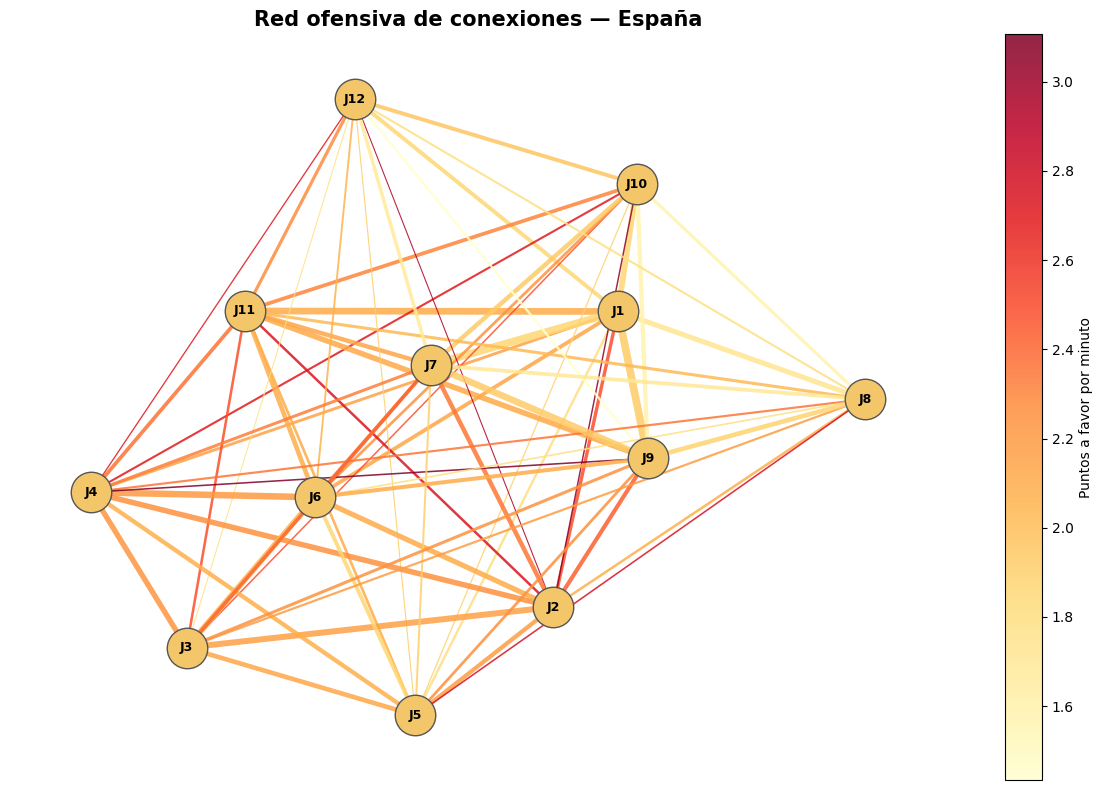

In [33]:
# Recupero valores cada enlace
valores_ataque = [
    G_ofensiva[u][v]["ataque"]
    for u, v in G_ofensiva.edges()
]

minutos_ofensiva = [
    G_ofensiva[u][v]["minutos"]
    for u, v in G_ofensiva.edges()
]

#grosor, minutos compartidos
grosores_ofensiva = [
    0.5 + 5 * minutos / max(minutos_ofensiva)
    for minutos in minutos_ofensiva
]

#dibujo red ofensiva
plt.figure(figsize=(12, 8))

nx.draw_networkx_nodes(
    G_ofensiva,
    pos,
    node_size=850,
    node_color="#F4C66A",
    edgecolors="#555555"
)

enlaces = nx.draw_networkx_edges(
    G_ofensiva,
    pos,
    width=grosores_ofensiva,
    edge_color=valores_ataque,
    edge_cmap=plt.cm.YlOrRd,
    edge_vmin=min(valores_ataque),
    edge_vmax=max(valores_ataque),
    alpha=0.85
)

nx.draw_networkx_labels(
    G_ofensiva,
    pos,
    font_size=9,
    font_weight="bold"
)

# Barra de colores
barra = plt.colorbar(enlaces, ax=plt.gca())
barra.set_label("Puntos a favor por minuto")

plt.title(
    "Red ofensiva de conexiones — España",
    fontsize=15,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()

#guardo la imagen
ruta_red_ofensiva = CARPETA_REDES / "red_ofensiva.png"
plt.savefig(ruta_red_ofensiva, dpi=300, bbox_inches="tight")

plt.show()

igual que antes, hago la tabla para verlo mejor con las mismas columnas.

la columna de pf_min son los minutos anotados por españa por cada minuto compartido por esa pareja en la cancha

pf son los puntos totales anotados (puntos a favor)

In [34]:
#10 parejas con mayor produccion ofensiva
top_parejas_ofensivas = (
    df_parejas_red[
        [
            "Jugadora_1",
            "Jugadora_2",
            "PF_Min",
            "PF",
            "Min",
            "Partidos"
        ]
    ]
    .sort_values("PF_Min", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

#valores, tabla sea + clara
top_parejas_ofensivas["PF_Min"] = (
    top_parejas_ofensivas["PF_Min"].round(3)
)

top_parejas_ofensivas["Min"] = (
    top_parejas_ofensivas["Min"].round(1)
)

display(top_parejas_ofensivas)

,Jugadora_1,Jugadora_2,PF_Min,PF,Min,Partidos
0,J4,J9,3.106,41,13.2,5
1,J2,J10,3.043,35,11.5,4
2,J2,J12,2.951,18,6.1,2
3,J5,J8,2.761,37,13.4,2
4,J2,J11,2.734,73,26.7,5
5,J4,J12,2.708,26,9.6,1
6,J4,J10,2.701,57,21.1,6
7,J3,J11,2.482,69,27.8,7
8,J1,J2,2.481,100,40.3,7
9,J3,J10,2.479,30,12.1,6


**LA PRIMERA TABLA MUESTRA LA MAXIMA PRODUCION OFENSIVA OBSERVADA**

j4-j9 tiene mas puntos 3,106 por minuto pero solo acumula 13,2 minutos

con j2-j12 pasa lo mismo, un valor ofensivo muy alto pero solo con 6,1 minutos y 2 partidos

no puedo asegurar que sean las mejores parejas porque la muestra es muy pequeña

con mas tiempo destaca j2-j11 con 26,7 min y j4-j10  con 21,1 min  -> algo mas solido

como busco algo mas solido voy a ver que parejas han estado mas minutos en pista , al menos 20 minutos juntas

**SEGUNDA TABLA : PAREJAS OFESNIVAS MAS CONSISTENTE**

In [35]:
top_ofensivas_fiables = (
    df_parejas_red[
        df_parejas_red["Min"] >= 20
    ][
        [
            "Jugadora_1",
            "Jugadora_2",
            "PF_Min",
            "PF",
            "Min",
            "Partidos"
        ]
    ]
    .sort_values("PF_Min", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

#redondeo
top_ofensivas_fiables["PF_Min"] = (
    top_ofensivas_fiables["PF_Min"].round(3)
)

top_ofensivas_fiables["Min"] = (
    top_ofensivas_fiables["Min"].round(1)
)

display(top_ofensivas_fiables)


,Jugadora_1,Jugadora_2,PF_Min,PF,Min,Partidos
0,J2,J11,2.734,73,26.7,5
1,J4,J10,2.701,57,21.1,6
2,J3,J11,2.482,69,27.8,7
3,J1,J2,2.481,100,40.3,7
4,J2,J9,2.421,123,50.8,7
5,J3,J7,2.400,102,42.5,7
6,J4,J11,2.356,106,45.0,6
7,J4,J8,2.350,51,21.7,5
8,J6,J7,2.341,92,39.3,7
9,J2,J7,2.339,131,56.0,7


la j2-j11  2,734 pf_min , 73 puntos en 26,7 minutos

j4-10 2,701 pf_min 57 pts en 21,1 min  -> parejas con mayor ritmo PEROOOO acumulan menos puntos que otras combinaciones  



**conclsuion de las 2 tablas :**

j1-j2 2,481 pf_min en 40,3 min

j2-j9 2,421  pfmin en 50,8 min

j3-j7 2,4 pf min en 42,5 min

j2-j7 2,339 pfmin en 56 min

**IMPORTANTEEEE!!!** sus valores no son los mas altos pero se mantienen durante bastante tiempo y aparecen en los 7 partidos (lo que todo entrenador desea) -> un buen funcionamiento ofensivo


**tengo que diferenciar entre:**

**volumen ->** muchos minutos y muchos puntos totales

**eficiencia ->** puntos producidos por cada minuto compartido

j2-j7 -> continuidad y fiabilidad  acumula mas minutos 56 (unos 8 minutos por partido) , tiene 131 puntos totales  aunque esté en la ultima posicion del top 10

j2 está relacionada con las 10 parejas y ademas con las conexiones ofensivas eficientes.

aunque ojo j2-j7 en sus 131 puntos son los puntos anotados por todo el equipo mientras ambas estan en pista, no los individualmente anotados por ellas. Pero quiere decir que funciona!!! puede que den muchas asistencias o sepan guiar al equipo ! me recuerda a denis rodman cuando solo hacia asistencias y no anotaba nada , pero cuando estaba en pista el equipo ganaba

POSIBLE INTERPRETACION cosas que no se ven en los datos : crear asistencias que terminen en canasta, organizamiento de ataque, generar espacios para anotacion, marcar el ritmo , cometer menos perdidas , facilitar transiciones o segundas oportunidades....

**RED DEFENSIVA**

Pc_min son los puntos recibidos por españa (pts encontra) por minuto mientras una pareja comparte pista


verde -< pocos puntos recibidos -> mejor resultado defensivo

rojo -> muchos puntos recibidos -> peor resultado defensivo

grosor -> min compartidos (idem anterior)

In [36]:
G_defensiva = nx.Graph()

#pongo las parejas y sus datos defensivos
for _, fila in df_parejas_red.iterrows():
    G_defensiva.add_edge(
        fila["Jugadora_1"],
        fila["Jugadora_2"],
        defensa=float(fila["PC_Min"]),
        minutos=float(fila["Min"])
    )

print("Número de jugadoras:", G_defensiva.number_of_nodes())
print("Número de parejas:", G_defensiva.number_of_edges())

Número de jugadoras: 12
Número de parejas: 65


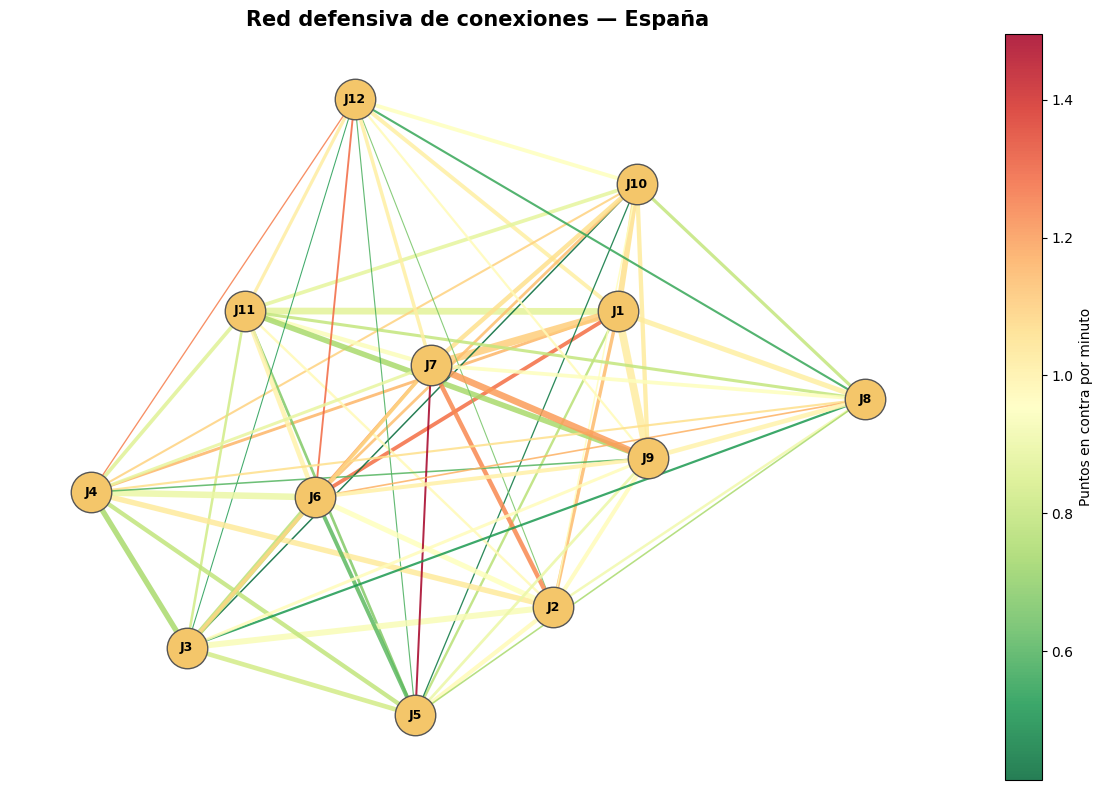

In [37]:
#recupero los valores de los enlaces
valores_defensa = [
    G_defensiva[u][v]["defensa"]
    for u, v in G_defensiva.edges()
]

minutos_defensa = [
    G_defensiva[u][v]["minutos"]
    for u, v in G_defensiva.edges()
]

#grosor son los minutos compartidos
grosores_defensa = [
    0.5 + 5 * minutos / max(minutos_defensa)
    for minutos in minutos_defensa
]

# Dibujo red defensiva
plt.figure(figsize=(12, 8))

nx.draw_networkx_nodes(
    G_defensiva,
    pos,
    node_size=850,
    node_color="#F4C66A",
    edgecolors="#555555"
)

enlaces_defensivos = nx.draw_networkx_edges(
    G_defensiva,
    pos,
    width=grosores_defensa,
    edge_color=valores_defensa,
    edge_cmap=plt.cm.RdYlGn_r,
    edge_vmin=min(valores_defensa),
    edge_vmax=max(valores_defensa),
    alpha=0.85
)

nx.draw_networkx_labels(
    G_defensiva,
    pos,
    font_size=9,
    font_weight="bold"
)

#pongo la barra de colores
barra = plt.colorbar(enlaces_defensivos, ax=plt.gca())
barra.set_label("Puntos en contra por minuto")

plt.title(
    "Red defensiva de conexiones — España",
    fontsize=15,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()

#guardo la imagen
ruta_red_defensiva = CARPETA_REDES / "red_defensiva.png"
plt.savefig(ruta_red_defensiva, dpi=300, bbox_inches="tight")

plt.show()

ahora la tabla para verlo mejor, idem que antes primero el ranking entero y despues aplico el minimo de 20 min

**TABLA : 10 PAREJAS CON MENOR PC_MIN**

ojo!!!! **ordeno de menor a mayor** porque hablando defensivamente -> **recibir menos puntos por minuto es mejor**

In [38]:
#10 parejas q reciben menos puntos x min
top_parejas_defensivas = (
    df_parejas_red[
        [
            "Jugadora_1",
            "Jugadora_2",
            "PC_Min",
            "PC",
            "Min",
            "Partidos"
        ]
    ]
    .sort_values("PC_Min", ascending=True)
    .head(10)
    .reset_index(drop=True)
)

#redondeo valores
top_parejas_defensivas["PC_Min"] = (
    top_parejas_defensivas["PC_Min"].round(3)
)

top_parejas_defensivas["Min"] = (
    top_parejas_defensivas["Min"].round(1)
)

display(top_parejas_defensivas)


,Jugadora_1,Jugadora_2,PC_Min,PC,Min,Partidos
0,J3,J10,0.413,5,12.1,6
1,J5,J10,0.444,4,9.0,4
2,J3,J8,0.524,12,22.9,5
3,J3,J12,0.536,3,5.6,3
4,J8,J12,0.563,12,21.3,3
5,J5,J12,0.588,4,6.8,2
6,J4,J9,0.606,8,13.2,5
7,J5,J6,0.620,30,48.4,6
8,J2,J12,0.656,4,6.1,2
9,J5,J11,0.676,20,29.6,6


j3-j10 estan en la cabeza con 0,413 pcmin y recibió solo 5 pts en 12,1 minutos

j5-j10 tiene 0,444 pcmin pero solo jugó 9 minutos

j3-j12 tabmien aparece muy arriba aunque solo jugó 5,6 min


resultados muy buenos!!! pero todavia sensibles por los pocos minutos

**TABLA 2:  RANKING DEFENSIVO CON AL MENOS 20 MIN**

PCmin son los puntos recibidos por españa por minuto con cada pareja en cancha

pc los ppuntos totales recibidos durante esos min

partidos los encuentros en los que aparecio la parejo

In [39]:
top_defensivas_fiables = (
    df_parejas_red[
        df_parejas_red["Min"] >= 20
    ][
        [
            "Jugadora_1",
            "Jugadora_2",
            "PC_Min",
            "PC",
            "Min",
            "Partidos"
        ]
    ]
    .sort_values("PC_Min", ascending=True)
    .head(10)
    .reset_index(drop=True)
)

# Redondeo
top_defensivas_fiables["PC_Min"] = (
    top_defensivas_fiables["PC_Min"].round(3)
)

top_defensivas_fiables["Min"] = (
    top_defensivas_fiables["Min"].round(1)
)

display(top_defensivas_fiables)

,Jugadora_1,Jugadora_2,PC_Min,PC,Min,Partidos
0,J3,J8,0.524,12,22.9,5
1,J8,J12,0.563,12,21.3,3
2,J5,J6,0.620,30,48.4,6
3,J5,J11,0.676,20,29.6,6
4,J3,J4,0.743,52,70.0,7
5,J9,J11,0.745,53,71.1,7
6,J1,J5,0.778,20,25.7,6
7,J3,J6,0.784,58,74.0,7
8,J4,J5,0.795,43,54.1,6
9,J8,J11,0.798,28,35.1,5


**mejores valores defensivos**

j3-j8 primera posicion xk solo recibió 12 pts en 22,9 minutos en 0,524 pc_min

j8-j12 tb con 12 ptos recibidos y algo + de 21 min

**j5-j9  un valor muy bueno!!!** 0,620 de pc_min con 48,4 minutos ESTA ES LA MAS INTERESANTE!!! OJO!!! se mantiene durante una muestra mayor que el resto

j5-j11 tiene tambien un buen equilibrio  cerca de los 30 min y 0,676 pcmin

**jugadoras q se repiten :** j8 con j3, j12 y j4 , la j5 con j9,j11 y otras y por ultimo la j9 que tiene conexiones defensivas durante mucho tiempo

**NUEVO BLOQUE : CENTRALIDADES**

CENTRALIDAD GENERAL X MIN

INFLENCIA OFENSIVA / DEFENSIVA

TABLA

**CENTRALIDAD PONDERADA**

Como tengo 65 de 66 parejas posibles , contar las conexiones no aporta nda , por eso necesito usar el peso de las conexiones


**centralidad ponderada: S_i = sumatoria _j Min_ij**

a ver, a cada jugador le sumo los minutos que comparte con todas sus compañeros..

un jugador con valor alto participa de manera + intensa en la estructura de rotaciones

**centralidad general x minutos -> ojo!!!** no representa los minutos reales jugados por cada jugador. Cada min aparece una vez x cada compañero con el que comparte la cancha.

**ojo! en basket** un jugador coincide con otros 4 -> la centralidad será aprox 4 veces su tiempo real

In [40]:
#centralidad ponderada x minutos
centralidad_general = dict(
    G_general.degree(weight="minutos")
)

#hago la tabla
df_centralidad_general = pd.DataFrame(
    centralidad_general.items(),
    columns=["Jugadora", "Centralidad_Minutos"]
)

# Ordeno de mayor a menor
df_centralidad_general = (
    df_centralidad_general
    .sort_values("Centralidad_Minutos", ascending=False)
    .reset_index(drop=True)
)

# Redondeo
df_centralidad_general["Centralidad_Minutos"] = (
    df_centralidad_general["Centralidad_Minutos"].round(1)
)

display(df_centralidad_general)

,Jugadora,Centralidad_Minutos
0,J1,631.0
1,J7,580.2
2,J9,578.0
3,J6,533.9
4,J11,521.3
5,J2,488.8
6,J4,460.3
7,J3,428.2
8,J10,400.9
9,J8,363.0


pongo la estimacion!!! recordando que la centralidad será aprox 4 veces su tiempo real

centralidad minutos -> intensidad total de sus conexiones dentro de la red

min_estimados es la aprox del tiempo real jugado

si el valor es elevado -> quiere decir que la jugadora aparece en muchas combinaciones pero no quiere decir que su rendimiento sea mejor!! ojo!!

In [41]:
df_centralidad_general["Minutos_Estimados"] = (
    df_centralidad_general["Centralidad_Minutos"] / 4
).round(1)

display(df_centralidad_general)

,Jugadora,Centralidad_Minutos,Minutos_Estimados
0,J1,631.0,157.8
1,J7,580.2,145.0
2,J9,578.0,144.5
3,J6,533.9,133.5
4,J11,521.3,130.3
5,J2,488.8,122.2
6,J4,460.3,115.1
7,J3,428.2,107.0
8,J10,400.9,100.2
9,J8,363.0,90.8


ahora veo las jugadoras que ocupan el centro de la estructura de las rotaciones

destaca j1 con la centralidad + alta, 631 que es como unos 157,8 minutos reales estimados

tengo tambien a j7 y j9 de + o - 145 minutos cada una

j6 y j11  -> tienen la mayor presencia


j12 la que tiene menor centralidad


ojo!!! si recuerdo la red general j1, j7 y j9  confirma que forman el nucleo con mayor presencia en las rotaciones

como son 7 partidos -> mejor añadir una columna con los minutos estimados por encuentro

In [42]:
#minutos medios estimados x partido
df_centralidad_general["Minutos_por_Partido"] = (
    df_centralidad_general["Minutos_Estimados"] / 7
).round(1)

display(df_centralidad_general)


,Jugadora,Centralidad_Minutos,Minutos_Estimados,Minutos_por_Partido
0,J1,631.0,157.8,22.5
1,J7,580.2,145.0,20.7
2,J9,578.0,144.5,20.6
3,J6,533.9,133.5,19.1
4,J11,521.3,130.3,18.6
5,J2,488.8,122.2,17.5
6,J4,460.3,115.1,16.4
7,J3,428.2,107.0,15.3
8,J10,400.9,100.2,14.3
9,J8,363.0,90.8,13.0


**CENTRALIDAD OFENSIVA PONDERADA**


Me toca calcular los pts x min  asociados a cada jugador (hay que tener en cuenta los minutos de todas las conexiones)

un valor alto me va a decir que el equipo mantuvo una produccion ofensiva elevada cuando ese jugador estaba en pista (considerando las conexiones y ponderandolas x minutos)

no van a ser sus puntos individuales -> será el rendimiento ofensivo colectivo asociado a su presencia

recorro la lista de las jugadoras

sumo los ptos y minutos de las conexiones

centralidad ofensiva = pf total / minutos total

convierto en tabla y ordeno

In [43]:
#lista de jugadoras
jugadoras = sorted(
    set(df_parejas_red["Jugadora_1"]) |
    set(df_parejas_red["Jugadora_2"]),
    key=numero_jugadora
)

resultados_ofensivos = []

for jugadora in jugadoras:

    #cojo todas las parejas en las que aparece
    conexiones = df_parejas_red[
        (df_parejas_red["Jugadora_1"] == jugadora) |
        (df_parejas_red["Jugadora_2"] == jugadora)
    ]

    #sumo pts y minutos de todas sus conexiones
    pf_total = conexiones["PF"].sum()
    minutos_total = conexiones["Min"].sum()

    # Producion ofensiva ponderada
    centralidad_ofensiva = pf_total / minutos_total

    resultados_ofensivos.append({
        "Jugadora": jugadora,
        "Centralidad_Ofensiva": centralidad_ofensiva
    })

#tabla de resultados
df_centralidad_ofensiva = pd.DataFrame(resultados_ofensivos)

# Ordeno de mayor a menor
df_centralidad_ofensiva = (
    df_centralidad_ofensiva
    .sort_values("Centralidad_Ofensiva", ascending=False)
    .reset_index(drop=True)
)

df_centralidad_ofensiva["Centralidad_Ofensiva"] = (
    df_centralidad_ofensiva["Centralidad_Ofensiva"].round(3)
)

display(df_centralidad_ofensiva)

,Jugadora,Centralidad_Ofensiva
0,J2,2.300
1,J4,2.285
2,J3,2.205
3,J11,2.202
4,J6,2.105
5,J5,2.074
6,J7,2.027
7,J9,2.014
8,J10,1.996
9,J1,1.965


**ojo!!! mirando la tabla la centralidad general y la ofensiva no dan los mismos resultados!!!**

conclusion ofensiva:

j2 ocupa el primer puesto , tiene 2,3 cuando está en sus distintas conexions, y el equipo anota aprox 2,3 pts por minuto

j4 está muy cerca de 2,285

j3 y j11 -> 2,2 aprox

j8 es el valor más bajo con 1,895


**interesante!** j1 era la jugadora con mayor centralidad por minutos y ahora está en la 10 posición con 1,965 . lo que quiere decir que tener mayor presencia en la red no quiere decir que su ritmo ofensivo sea mayor . j1 va a ser fundamental en la rotacion del equipo pero las conexiones de j2 y j4 son superiores

**CENTRALIDAD DEFENSIVA PONDERADA**

un valor menor será mejor

un **valor bajo** -> el equipo recibe pocos pts x min durante las conexiones de esa jugadora

**valor alto**-> el equipo recibe + pts por min

**ojo!!! es un dato colectivo asociado a su presencia y no una medida pura de su defensa individial**

creo una lista vacia

In [44]:
resultados_defensivos = []


recorro las jugadoras , busco las parejas en las que aparece esa jugadora

sumo todos los puntos recibidos los pc y todos los minutos compartidos por las conexiones

centralidad defensiva= pc total / minutos total

guardo el nombre del jugador en la lista del dataframe y luego lo hago tabla

ordeno de menos a mas porque recibir menos es mejor

In [45]:
for jugadora in jugadoras:

    #cojo todas las parejas en las que aparece
    conexiones = df_parejas_red[
        (df_parejas_red["Jugadora_1"] == jugadora) |
        (df_parejas_red["Jugadora_2"] == jugadora)
    ]

    #sumo los pts recibidos y los minutos
    pc_total = conexiones["PC"].sum()
    minutos_total = conexiones["Min"].sum()

    # Pts recibidos x minuto, ponderados x el tiempo
    centralidad_defensiva = pc_total / minutos_total

    resultados_defensivos.append({
        "Jugadora": jugadora,
        "Centralidad_Defensiva": centralidad_defensiva
    })

#tabla
df_centralidad_defensiva = pd.DataFrame(
    resultados_defensivos
)

#ordeno de menor a mayor xk recibir menos es mejor!
df_centralidad_defensiva = (
    df_centralidad_defensiva
    .sort_values("Centralidad_Defensiva", ascending=True)
    .reset_index(drop=True)
)

df_centralidad_defensiva["Centralidad_Defensiva"] = (
    df_centralidad_defensiva["Centralidad_Defensiva"].round(3)
)

display(df_centralidad_defensiva)

,Jugadora,Centralidad_Defensiva
0,J5,0.825
1,J3,0.831
2,J11,0.875
3,J8,0.893
4,J4,0.912
5,J12,0.960
6,J10,0.968
7,J6,0.974
8,J9,0.983
9,J2,1.007


**destacan j5, j3 , j11 y j8**  y en el extermo contrario tengo j1 y j7 (no quiere decir que sean malas defensoras) quiere decir que el equipo recibió más puntos x minuto en el conjunto de conexiones en las que han participado ---> puede depender de sus compañeras , de los rivales y de todo el contexto.

**si comparo con la centralidad ofensiva ⁉**

j3 es la 3º ofensivamente y la 2º defensivamente  -> jugadora equilibrada

j11 es la 4º en ataque y 3º en defensa -> equilibrado

j4 es 2º ofensivamente y 5º en defensa

j5 es la 6 en ataque y 1 en defensa ojo! parece destacar en rendimiento defensivo asociado

j2 es la 1º ofensivamente pero 10 defensivamente  -> es mejor en ataque !

**MEJOR REUNIR TODO EN UNA UNICA TABLA Y PODER COMPARAR MEJOR**

BALANCE= PUNTOS ANOTADOS POR MINUTO - PUNTOS RECIBIDOS POR MINUTO

si es mas grande el valor -> será mas favorable la diferencia entre ataque y defensa durante las conexiones

centralidad minutos -> cuanto participa una jugadora en la estructura

centralidad ofensiva -> produccion ofensiva colectiva asociada

centralidad defensiva -> puntos recibidos asociados y cuanto mas pequeña mejor

balance es la diferencia entre ataque y defensa

In [46]:
#junto la centralidad general + la ofensiva
df_centralidades = df_centralidad_general.merge(
    df_centralidad_ofensiva,
    on="Jugadora"
)

#añado la centralidad defensiva
df_centralidades = df_centralidades.merge(
    df_centralidad_defensiva,
    on="Jugadora"
)

#calculo el balance entre ataque y defensa
df_centralidades["Balance"] = (
    df_centralidades["Centralidad_Ofensiva"]
    - df_centralidades["Centralidad_Defensiva"]
).round(3)

#ordeno x el balance
df_centralidades = (
    df_centralidades
    .sort_values("Balance", ascending=False)
    .reset_index(drop=True)
)

display(df_centralidades)

,Jugadora,Centralidad_Minutos,Minutos_Estimados,Minutos_por_Partido,Centralidad_Ofensiva,Centralidad_Defensiva,Balance
0,J3,428.2,107.0,15.3,2.205,0.831,1.374
1,J4,460.3,115.1,16.4,2.285,0.912,1.373
2,J11,521.3,130.3,18.6,2.202,0.875,1.327
3,J2,488.8,122.2,17.5,2.300,1.007,1.293
4,J5,349.0,87.2,12.5,2.074,0.825,1.249
5,J6,533.9,133.5,19.1,2.105,0.974,1.131
6,J9,578.0,144.5,20.6,2.014,0.983,1.031
7,J10,400.9,100.2,14.3,1.996,0.968,1.028
8,J8,363.0,90.8,13.0,1.895,0.893,1.002
9,J12,266.8,66.7,9.5,1.934,0.960,0.974


ojo!!! destaca j3 que tiene el mayor balance 1,374 y luego le sigue j4

j11 está en la 3º con un balance de 1,327

j2 es la mejor en produccion ofensiva 2,3 pero su mayor valor defensivo recibido es 1,007

j5 no está entre ls primeras ofensivamente pero tiene un buen resultado defensivo 0,825

j1 y j7 son las que tiene mayor presencia en rotaciones -> pero tienen balances mas bajos

guardo la tabla

In [47]:
ruta_centralidades = (
    CARPETA_REDES / "centralidades_jugadoras.csv"
)

df_centralidades.to_csv(
    ruta_centralidades,
    index=False,
    encoding="utf-8-sig"
)

print("Tabla guardada en:", ruta_centralidades)

Tabla guardada en: /content/drive/MyDrive/TFG_UGR/Redes_UGR/centralidades_jugadoras.csv


**NUEVO PUNTO : OPTIMIZACION DE LOS QUINTETOS OFENSIVOS / DEFENSIVOS / EQUILIBRADOS**

este puede que sea la parte más importante!!! me he basado en el artículo “Two stage Student team Formation in Practice”.

un quinteto contiene 10 parejas , evaluo el quinteto con estas parejas pero no sumando las centralidades individuales.

combinatios es para crear todas las parejas posibles dentro del mismo grupo
numpy es para los calculos


In [48]:
from itertools import combinations
import numpy as np

primero hago un diccionario vacio

recorro la tabla de parejas red fila x fila (cada fila era una preja )

cojo las 2 jugadoras y las ordeno con numero_jugadora -> hago la tupla es decir pasar de los [] a los () y las guardo y asi se me queda el diccionario mejor organizado para verlo mejor


el diccionario me viene bien para encontrar los datos de cada conexion sin recorrer la misma tabla una y otra vez

In [49]:
#hago dicionario con la información de cada pareja
datos_parejas = {}

for _, fila in df_parejas_red.iterrows():

    pareja = tuple(sorted(
        [fila["Jugadora_1"], fila["Jugadora_2"]],
        key=numero_jugadora
    ))

    datos_parejas[pareja] = {
        "PF_Min": fila["PF_Min"],
        "PC_Min": fila["PC_Min"],
        "Min": fila["Min"]
    }

print("Parejas disponibles:", len(datos_parejas))

Parejas disponibles: 65


hago la funcion evaluar quinteto  , cada vez que coja los 5 jugadores hace todos los calculos y con combinations hago todas las combinaciones de las jugadoras en ese quinteto -> luego hago la lista

ojo! necesito 3 listas

valores pf -> los puntos a favor x minuto de cda pareja

valores pc -> los puntos en contra x minuto

minutos que son los compartidos

analizo y ordeno

In [50]:
def evaluar_quinteto(quinteto):

    #hago las 10 parejas internas del quinteto
    parejas_quinteto = list(combinations(quinteto, 2))

    valores_pf = []
    valores_pc = []
    minutos = []

    for jugadora_1, jugadora_2 in parejas_quinteto:

        pareja = tuple(sorted(
            [jugadora_1, jugadora_2],
            key=numero_jugadora
        ))

        # Si una pareja nunca apareció, no se puede evaluar el quinteto
        if pareja not in datos_parejas:
            return None

        valores_pf.append(
            datos_parejas[pareja]["PF_Min"]
        )

        valores_pc.append(
            datos_parejas[pareja]["PC_Min"]
        )

        minutos.append(
            datos_parejas[pareja]["Min"]
        )

    # Promedio de las 10 conexiones
    ataque = np.mean(valores_pf)
    defensa = np.mean(valores_pc)
    equilibrio = ataque - defensa

    return {
        "Ataque": ataque,
        "Defensa": defensa,
        "Equilibrio": equilibrio,
        "Min_Pareja": min(minutos),
        "Media_Min_Parejas": np.mean(minutos)
    }

va a salir un quinteto de prueba inicial pero ojo! que no va a ser el optimo

es para comprobar que la funcion funciona antes de empezar

In [51]:
quinteto_prueba = ("J2", "J3", "J4", "J5", "J11")

resultado_prueba = evaluar_quinteto(
    quinteto_prueba
)

print("Quinteto de prueba:", quinteto_prueba)
print("Resultado:", resultado_prueba)

Quinteto de prueba: ('J2', 'J3', 'J4', 'J5', 'J11')
Resultado: {'Ataque': np.float64(2.2685783631467595), 'Defensa': np.float64(0.8644892618279716), 'Equilibrio': np.float64(1.404089101318788), 'Min_Pareja': 26.7, 'Media_Min_Parejas': np.float64(51.489999999999995)}


funciona bien no aparece ningun none

**BUSQUEDA DE LOS QUINTETOS OPTIMOS**

Ya he definido la funcion que evalua el rendimiento conjunto (10 parejas) -> busco las combinaciones de las 5 jugadores que tengan el mejor comportamiento ofensivo/defensivo /equilibrado -> uso optimizacion  

importo las librerias

radom elijo los jugadores y me va a generar los quintetos vecinos

math es la libreria de matematicas para la probabilidad

In [52]:
import random
import math

creo la nueva fucnion obtener valor que recibe el resultado que es el diccionario generado x evaluar quinteto y objetivo que es lo que quiero optimizar

si el quinteto no puede evaluarse , si falta alguna de las 10 parejas  devuelve none y obtener valor me devuelve -np.inf (menos infinito)

es como decir que ese quinteto no puede evaluarse y se considera peor que cualquier otro quinteto

luego con if objetivo == ataque --> el valor ofensivo , si se busca defensa  pues lo mismo

siempre busca el valor mas alto

devuelve ataque - defensa

In [53]:
def obtener_valor(resultado, objetivo):

    #quinteto sin datos completos no puede evaluarse
    if resultado is None:
        return -np.inf

    if objetivo == "Ataque":
        #si es mayor el ataque mejor
        return resultado["Ataque"]

    elif objetivo == "Defensa":
        # Como recibir menos puntos es mejor, cambio el signo para poder maximizar
        return -resultado["Defensa"]

    elif objetivo == "Equilibrio":
        #cuanto mayor sea la diferencia mejor
        return resultado["Equilibrio"]

    else:
        raise ValueError(
            "El objetivo debe ser Ataque, Defensa o Equilibrio"
        )

ahora quiero una funcion que crea un quinteto nuevo y parecido al que ya tengo

solo tengo que sustituir un jugador , recibe el quinteto actual que son las 5 jugadores de la solucion que ya tenia y las jugadoras que es la lista completa de las 12


entonces cojo el quinteto de la lista y elijo aleatoriamente una de sus 5 jugadoras , se ve quien entra con jugadora_entra, selecciona aleatoriamente 1 de las 7 disponibles  y retira a la jugadora elejida -> se forma un nuevo grupo copiando todas las jugadoras menos la que ha salido y luego añade la nueva jugadora

me falta ordenar la tupla de jugadoras ("j2", "j3", "j4", ...) y devuelve el quinteto

es quinteto vecino porque en realidad los 2 quintetos tienen 4 jugadores iguales y solo 1 diferente

In [54]:
def generar_vecino(quinteto_actual, jugadoras):

    #escojo 1 jugador para retirar
    jugadora_sale = random.choice(
        list(quinteto_actual)
    )

    #busco jugadores que no esten en el quinteto
    disponibles = [
        jugadora
        for jugadora in jugadoras
        if jugadora not in quinteto_actual
    ]

    #escojo una nuevo jugador
    jugadora_entra = random.choice(disponibles)

    # Realizo el cambio
    nuevo_quinteto = [
        jugadora
        for jugadora in quinteto_actual
        if jugadora != jugadora_sale
    ]

    nuevo_quinteto.append(jugadora_entra)

    # Ordeno el quinteto
    nuevo_quinteto = tuple(sorted(
        nuevo_quinteto,
        key=numero_jugadora
    ))

    return nuevo_quinteto

ahora junto el algoritmo que realiza la busqueda , partiendo del quinteto de prueba

empiezo de un quintteo valido -> cambio al jugador de cada iteracion -> solo cojo los quintetos cuyas 10 parejas tengan al menos  20 min -> busco mejor ataque /defensa / equilibrio -> lo guardo (el mejor) -> da la evolucion para luego poder representarlo

**optimización:** parte de una distribución inicial, intercambia unidades entre quintetos y calcula si la nueva configuración mejora la función objetivo.
Las mejoras se aceptan siempre, mientras que lo que empeora pueden aceptarse con una probabilidad dependiente de la temperatura y eso les lleva a soluciones localmente buenas.

**La temperatura no es la parámetro real sino que está inspirado en el enfriamiento de los materiales.**

Al principio, el sistema está caliente y las unidades pueden moverse con libertad entre los quintetos. Por eso el algoritmo acepta las mejores configuraciones, aunque también puede elegir las malas.

**importante!! concepto de temperatura !** es la controla la probabilida de aceptar un cambio que empeore temporalmente el resultado

temperatura alta -> el algoritmo explora con + libertad

temperatura baja -> se vuelve + exigente y acepta mejoras




**método:** parte de un quinteto que se conoce, sustituye jugadoras una a una y luego compara las nueva combinaciones formadas. Al comienzo puede aceptar algunos empeoramientos para explorar y ver soluciones locales. Cuando disminuye la temperatura ,  termina conservando la mejor combinación encontrada. Por último, descarta muchos quintetos cuyas parejas no tengan menos de 20 min en pista.

**en la funcion llamada:**

**objetivo** -> indica si busco el mejor quinteto en ataque , defensa o equilibrio

**quinteto inicial** que es desde donde se comienza la busqueda

**interaccones**  es el numero de cambios que va a intentar realizar

**temperatura inicial** va a controlar la libertad inicial del algoritmo para aceptear soluciones peores

**enfriamiento** determina como disminuye la temperatura

**minimo minutos** que las 10 parejas tengan al menos 20 min

**semilla** para repetir el experimento y obtener el mismo resultado

**FORMA DE HACERLO:**
uso : temperatura = temperatura * enfriamiento

enfriamiento de 0,995 (como el alfa del artículo)

cambia una jugadora

evalua el quinteto

acepta siempres si mejora con  en el código diferencia >0

acepta a veces que se empeora , con el código seria random < exp(diferencia/T)

conserva la solución en mejor_quinteto

**Matemáticamente:**

se calcula la diferencia entre el valor nuevo del quinteto (vecino) y el que tenemos ahora

si delta > 0 el nuevo quinteto se acepta porque mejora el resultado , si delta   <0, se acepta con la probabilidad P= exp( delta/T)

**La temperatura disminuye en cada interacción  y usamos  . Si baja T, también disminuye la probabilidad de aceptar quintetos peores**

Para mi  delta vecino y delta actual son para ataque /defensa / equilibrio:

ataque : media de pf_min de las 10 parejas

defensa:  negativo de la media de pc_min

equilibrio : ataque menos defensa

si delta mayor que cero , lo acepto directamente . Si delta es menor, lo acepto solamente cuando un número aleatorio entre 0 y 1 sea menor que exp(delta/T)
luego reduzco la temperatura multiplicando por 0,995  ,

temperatura= temperatura * enfriamiento

T_ n +1 = 0,995 T_n

Empiezo con T₀ = 1 , se realizan 5000 iteraciones y solo me quedo con los quintetos cuyas 10 parejas tengan al menos 20 minutos . Y siempre conservo por separado el mejor quinteto encontrado.

In [55]:
def buscar_quinteto_optimo(
    objetivo,
    quinteto_inicial,
    iteraciones=5000,
    temperatura_inicial=1.0,
    enfriamiento=0.995,
    minimo_minutos=20,
    semilla=42
):

    #fijo la semilla para poder repetir el resultado
    #random seed utiliza elecciones aleatorias para decidir
    #quien entra, sale o aceptar una solucion peor
    random.seed(semilla)

    #evaluo el quinteto inicial
    #convierte en una tupla
    #quinteto actual es la posicion desde la que se mueve
    quinteto_actual = tuple(quinteto_inicial)
    resultado_actual = evaluar_quinteto(
        quinteto_actual
    )

    #comprueboo que el quinteto inicial es valido
    #si es none falta informacion
    if (
        resultado_actual is None
        #alguna pareja tiene al menos 20 minutos
        or resultado_actual["Min_Pareja"] < minimo_minutos
    ):
    #si el quinteto no es valido el programa se detiene
        raise ValueError(
            "El quinteto inicial no cumple los requisitos"
        )
    #para obtener el valor que quiero optimizar
    #extrae un unico num si busco ataque saca 1 d ataque..
    valor_actual = obtener_valor(
        resultado_actual,
        objetivo
    )

    #la mejor solucion es la inicial
    #guardo primeramente la mejor solucion
    #es el quinteto inicial
    mejor_quinteto = quinteto_actual
    #el que contiene las metricas
    mejor_resultado = resultado_actual
    #el num utilizado para compararlo
    mejor_valor = valor_actual

    # Temperatura inicial
    temperatura = temperatura_inicial

    # Guardo la evolucion del mejor valor
    #hago la lista vacia que comienza con el quinteto inicial
    historial = [mejor_valor]

    for _ in range(iteraciones):

        # Genero un quinteto vecino
        #retira 1 jugador del quinteto actual
        #incorpora un jugador que estaba fuera
        quinteto_vecino = generar_vecino(
            quinteto_actual,
            jugadoras
        )
        #calculo las metricas de las 10parejas
        resultado_vecino = evaluar_quinteto(
            quinteto_vecino
        )

        # Rechazo quintetos sin datos suficientes
        #veo si falta alguna pareja
        # Veo si alguna pareja tiene menos de 20 min
        if (
            resultado_vecino is None
            or resultado_vecino["Min_Pareja"] < minimo_minutos
        ):
            #si ocurre alguno de los casos anteriores
            #el quinteto no se usa
            #reduce la temperatura aunque el vecino haya sido rechazado
            temperatura = temperatura * enfriamiento
            historial.append(mejor_valor)
            #pasa a la siguiente interaccion
            continue

        #saca el valor del objetivo que busco
        valor_vecino = obtener_valor(
            resultado_vecino,
            objetivo
        )


        #Comparar  el vecino con la solucion actual
        diferencia = valor_vecino - valor_actual

        # Acepto si mejora o con cierta probabilidad
        if (
            diferencia > 0
            or random.random()
            < math.exp(
                diferencia / max(temperatura, 1e-12)
            )
        ):
            quinteto_actual = quinteto_vecino
            resultado_actual = resultado_vecino
            valor_actual = valor_vecino

        # Actualizo la mejor solucion encontrada
        if valor_actual > mejor_valor:
          #compruebo si la posicion actual supera al mejor resultado
          #si lo supera lo guardo
            mejor_quinteto = quinteto_actual
            mejor_resultado = resultado_actual
            mejor_valor = valor_actual

        #reduzco la temperatura
        temperatura = temperatura * enfriamiento

        # Guardo la evolución
        historial.append(mejor_valor)

    return (
        mejor_quinteto,
        mejor_resultado,
        historial
    )

busco los tres objetivos : mejor quinteto ofensivo / defensivo y equilibrado

In [56]:
# Busco el mejor quinteto ofensivo
quinteto_ofensivo, resultado_ofensivo, historial_ofensivo = (
    buscar_quinteto_optimo(
        objetivo="Ataque",
        quinteto_inicial=quinteto_prueba,
        semilla=42
    )
)

In [57]:
# Busco el mejor quinteto defensivo
quinteto_defensivo, resultado_defensivo, historial_defensivo = (
    buscar_quinteto_optimo(
        objetivo="Defensa",
        quinteto_inicial=quinteto_prueba,
        semilla=42
    )
)

In [58]:
# Busco el quinteto + equilibrado
quinteto_equilibrado, resultado_equilibrado, historial_equilibrado = (
    buscar_quinteto_optimo(
        objetivo="Equilibrio",
        quinteto_inicial=quinteto_prueba,
        semilla=42
    )
)

**TABLA RESUMEN**

Veré si hay jugadores que se repiten, los mejores quintetos

si hay equilibrio entre ataque y defensa ...

In [59]:
resultados_quintetos = [
    {
        "Tipo": "Ofensivo",
        "Quinteto": " - ".join(quinteto_ofensivo),
        "Ataque": resultado_ofensivo["Ataque"],
        "Defensa": resultado_ofensivo["Defensa"],
        "Equilibrio": resultado_ofensivo["Equilibrio"],
        "Min_Pareja": resultado_ofensivo["Min_Pareja"],
        "Media_Min_Parejas": resultado_ofensivo[
            "Media_Min_Parejas"
        ]
    },
    {
        "Tipo": "Defensivo",
        "Quinteto": " - ".join(quinteto_defensivo),
        "Ataque": resultado_defensivo["Ataque"],
        "Defensa": resultado_defensivo["Defensa"],
        "Equilibrio": resultado_defensivo["Equilibrio"],
        "Min_Pareja": resultado_defensivo["Min_Pareja"],
        "Media_Min_Parejas": resultado_defensivo[
            "Media_Min_Parejas"
        ]
    },
    {
        "Tipo": "Equilibrado",
        "Quinteto": " - ".join(quinteto_equilibrado),
        "Ataque": resultado_equilibrado["Ataque"],
        "Defensa": resultado_equilibrado["Defensa"],
        "Equilibrio": resultado_equilibrado["Equilibrio"],
        "Min_Pareja": resultado_equilibrado["Min_Pareja"],
        "Media_Min_Parejas": resultado_equilibrado[
            "Media_Min_Parejas"
        ]
    }
]

df_quintetos_optimos = pd.DataFrame(
    resultados_quintetos
)

# Redondeo las métricas
columnas_redondear = [
    "Ataque",
    "Defensa",
    "Equilibrio",
    "Min_Pareja",
    "Media_Min_Parejas"
]

df_quintetos_optimos[columnas_redondear] = (
    df_quintetos_optimos[columnas_redondear].round(3)
)

display(df_quintetos_optimos)


,Tipo,Quinteto,Ataque,Defensa,Equilibrio,Min_Pareja,Media_Min_Parejas
0,Ofensivo,J2 - J3 - J4 - J7 - J11,2.340,0.952,1.388,26.7,50.81
1,Defensivo,J3 - J4 - J5 - J6 - J11,2.156,0.804,1.352,27.8,55.29
2,Equilibrado,J2 - J3 - J4 - J8 - J11,2.285,0.867,1.418,21.7,42.68


**ojo!!!**

**quinteto ofensivo**, me incluye el j2 y j7 que ya aparecia en las conexiones

**quinteto defensivo**, es el que menos puntos recibe por minuto. Aparece j5 que era el primer jugador del ranking defensivo . Es el que tiene más minutos 55,29 minutos de media

**quinteto equilibrado**, j8 reemplaza al j7 respecto a lo ofensivo y mejora la defensa

**importante!!** j3, j4 y j11 aparecen en los tres quintetos -> sus conexiones son las mas valiosas para el equipo tanto ofensiva como defensivamente y confirma lo de las centralidades individuales

aunque de momento son los mejores quintetos encontrados por el algoritmo, no son los óptimos

**GRAFICA DE EVOLUCION DE LA OPTIMIZACION**

Hago 3 graficos el de ataque / defensa / equilibrio

la línea me va a representar la mejor solucion para cada iteraccion

se avanza mediante los escalones

si se encuentra un quinteto mejor -> cambia de nivel

preparo el historial defensivo, en la funcion de optimizacion se convierte la defensa en un problema de maximizacion (uso: resultado ["Defensa"])

si 0,80 pc/min se guarda como -0,80 , si 1,10 pc/min se guarda -1,10 (negativos para maximizar)  como -0,80 > -1,10 el algoritmo reconoce que 0,80 es mejor

luego en la grafica vuelvo a cambiar el signo!!! -> **cuanto + baja esté la linea -> mejor es la defensa**

eje [0] ofensivo, eje[1] el defensivo, el eje [2] el equilibrado

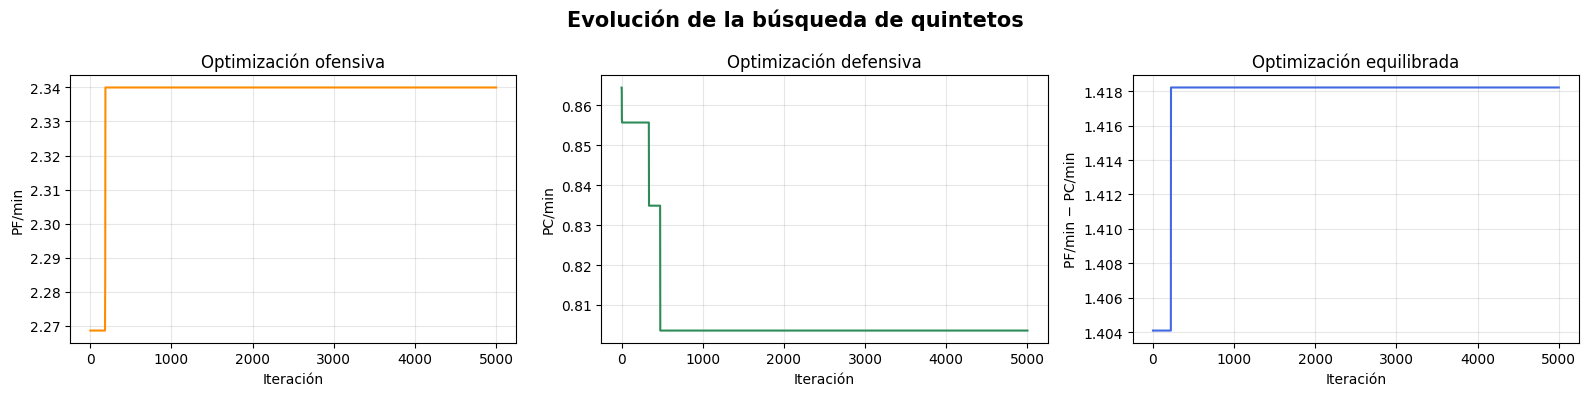

In [60]:
# Convierto el historial defensivo a PC/min reales.
# Durante la optimización: -PC/min para maximizar,
# pero en la grafica se enseña el valor positivo.
historial_defensa_real = [
    -valor for valor in historial_defensivo
]

fig, ejes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

# Evolucion del quinteto ofensivo
ejes[0].plot(
    historial_ofensivo,
    color="darkorange"
)

ejes[0].set_title("Optimización ofensiva")
ejes[0].set_xlabel("Iteración")
ejes[0].set_ylabel("PF/min")
ejes[0].grid(alpha=0.3)

# Evolucioon del quinteto defensivo
ejes[1].plot(
    historial_defensa_real,
    color="seagreen"
)

ejes[1].set_title("Optimización defensiva")
ejes[1].set_xlabel("Iteración")
ejes[1].set_ylabel("PC/min")
ejes[1].grid(alpha=0.3)

# Evolucioon del quinteto equilibrado
ejes[2].plot(
    historial_equilibrado,
    color="royalblue"
)

ejes[2].set_title("Optimización equilibrada")
ejes[2].set_xlabel("Iteración")
ejes[2].set_ylabel("PF/min − PC/min")
ejes[2].grid(alpha=0.3)

plt.suptitle(
    "Evolución de la búsqueda de quintetos",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    CARPETA_REDES / "evolucion_optimizacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**eje horizontal :** numero de la interacción

**eje vertical :** mejor valor de ataque encontrado hasta ese momento

**Ofensiva:** parte de 2,269 pf/min y encuentra muy rapido el quinteto (2,340) -> permanece estable  xk no encuentra otro que supere el resultado

**Defensiva:** baja hasta 0,864 pc/min hasta 0,804 pc/min ( los escalones es que ha habido 2 mejoras sucesivas) ojo! aquí bajar es mejorar

**equilibrada;** comienza en 1,404  y alcanza rápido el quinteto (1,418) luego se mantiene estable

**ESTABILIDAD CON DISTINTAS SEMILLAS!**

La idea es ejecutar la búsqueda varias veces desde recorridos aleatorios diferentes -> a ver si vuelve a dar los mismos 3 quintetos.

voy a probar 5 semillas distintas

para cada semilla ejecuto la optimizacion ofensiva/defensiva /equilibrada

se hacen 5 x 3= 15 busquedas

guardo el quinteto obtenido y sus 3 métricas

tabla

In [61]:
#Semillas a probar
semillas = [1, 7, 21, 42, 100]

#aqui voy a almacenar todos los resultados
resultados_estabilidad = []

una vez hecha la lista vacia donde voy a guardar todos los resultados que me salgan, recorro los 3 objetivos (primero encuentra el mejor quinteto ofensivo , luego el mejor quinteto defensivo y por ultimo el mejor equilibrado)

en la primera vuelta objetivo vale "ataque" , luego "defensa" y por ultimo " equilibrio"

In [62]:
# Repeto la optimización para los3 objetivos
for objetivo in ["Ataque", "Defensa", "Equilibrio"]:

    for semilla in semillas:
        #llamo a la funcion que ya hice y devuelve los 3 elementos
        quinteto, resultado, historial = buscar_quinteto_optimo(

            #indico que quiero optimizar
            objetivo=objetivo,
            #sisempre uso el mismo punto de partida
            quinteto_inicial=quinteto_prueba,
            #mantengo los parametros
            iteraciones=5000,
            temperatura_inicial=1.0,
            enfriamiento=0.995,
            minimo_minutos=20,
            semilla=semilla
        )
        #añado el nuevo elemento a lal ista
        resultados_estabilidad.append({
            "Objetivo": objetivo,
            "Semilla": semilla,
            "Quinteto": " - ".join(quinteto),
            "Ataque": resultado["Ataque"],
            "Defensa": resultado["Defensa"],
            "Equilibrio": resultado["Equilibrio"]
        })

creo el dataframe , transformo la lista en un diccionario

In [63]:
#tabla
df_estabilidad = pd.DataFrame(resultados_estabilidad)

# Redondeo
columnas_numericas = [
    "Ataque",
    "Defensa",
    "Equilibrio"
]

df_estabilidad[columnas_numericas] = (
    df_estabilidad[columnas_numericas].round(3)
)

display(df_estabilidad)

,Objetivo,Semilla,Quinteto,Ataque,Defensa,Equilibrio
0,Ataque,1,J2 - J3 - J4 - J7 - J11,2.340,0.952,1.388
1,Ataque,7,J2 - J3 - J4 - J7 - J11,2.340,0.952,1.388
2,Ataque,21,J2 - J3 - J4 - J7 - J11,2.340,0.952,1.388
3,Ataque,42,J2 - J3 - J4 - J7 - J11,2.340,0.952,1.388
4,Ataque,100,J2 - J3 - J4 - J7 - J11,2.340,0.952,1.388
5,Defensa,1,J3 - J4 - J5 - J6 - J11,2.156,0.804,1.352
6,Defensa,7,J3 - J4 - J5 - J6 - J11,2.156,0.804,1.352
7,Defensa,21,J3 - J4 - J5 - J6 - J11,2.156,0.804,1.352
8,Defensa,42,J3 - J4 - J5 - J6 - J11,2.156,0.804,1.352
9,Defensa,100,J3 - J4 - J5 - J6 - J11,2.156,0.804,1.352


el algoritmo es ESTABLE!!! respecto a las semilals probadas . aunque ha seguido 5 recorridos aleatorios diferentes siempre ha obtenido la misma solucion para cada objetivo

**VOY A CONFIRMAR SI SON LOS OPTIMOS GLOBALES DE VERDAD!**

**COMPARACION MEEDIANTE BUSQUEDA EXHAUSTIVA**

No voy a usar ni semillas, ni decisiones aleatorias -> solo evalúa uno por uno todos los quintetos posibles.

Si en la tabla salen los mismos 3 quintetos obtenidos por el algoritmo podría decir  y afirmar que se encontró los óptimos globales dentro de las restricciones definidas.

Se prueba los 792 quintetos posibles de las 12 jugadoras y se conserva solo aquellos cuyas 10 parejas tengan al menos 20 min.

creo lista vacia y genero los quinetos posibles 792 -> (12 5) = 12! / 5! 7! = 792 , el bucle lo recorre uno por uno

obtiene las 10 parejas del quinteto , busca los datos en datos_parejas, calcula ataque medio / defensa media / equilibrio + comprueba los min de las parejas

he puesto que devuelva none si falta algo de informacion

tiene que aplicar el minimo de minutos de la pareja menos utilizada dentro del quinteto ( para garantizar que todas las parejas tengan al menos 20 min) y los guarda, tabla

In [64]:
#Lista donde almaceno los quintetos validos
resultados_exhaustivos = []

#Genero todas las combinaciones posibles de 5 jugadoras
for quinteto in combinations(jugadoras, 5):

    # se miran las 10 parejas internas del quinteto
    resultado = evaluar_quinteto(quinteto)

    #Descarto quintetos incompletos o con parejas poco utilizadas
    if resultado is None:
        continue

    if resultado["Min_Pareja"] < 20:
        continue

    # Guardo el quinteto y sus resultados
    resultados_exhaustivos.append({
        "Quinteto": " - ".join(quinteto),
        "Ataque": resultado["Ataque"],
        "Defensa": resultado["Defensa"],
        "Equilibrio": resultado["Equilibrio"],
        "Min_Pareja": resultado["Min_Pareja"],
        "Media_Min_Parejas": resultado["Media_Min_Parejas"]
    })

#tabla
df_exhaustiva = pd.DataFrame(resultados_exhaustivos)

print("Quintetos posibles:", len(list(combinations(jugadoras, 5))))
print("Quintetos válidos:", len(df_exhaustiva))

Quintetos posibles: 792
Quintetos válidos: 83


solo 83 quintetos son válidos!  de los que existen datos para sus 10 parejas internas y que hayan tenido al menos 20 min

792-83 = 709 quintetos , es decir, 83/ 792 x 100 = 10,5% de los quintetos

la optimización se realiza sobre ese 10,5% de las combinaciones posibles , evitando coger quintetos sustentados en asociaciones con una muestra demasiado reducida

busco cual es el mejor quinteto para cada objetivo

In [65]:
# Mejor quinteto ofensivo: mayor PF/min
mejor_exhaustivo_ataque = df_exhaustiva.loc[
    df_exhaustiva["Ataque"].idxmax()
]

# Mejor quinteto defensivo: menor PC/min
mejor_exhaustivo_defensa = df_exhaustiva.loc[
    df_exhaustiva["Defensa"].idxmin()
]

# Mejor quinteto equilibrado: mayor diferencia PF/min - PC/min
mejor_exhaustivo_equilibrio = df_exhaustiva.loc[
    df_exhaustiva["Equilibrio"].idxmax()
]

# junto los tres resultados
df_mejores_exhaustivos = pd.DataFrame([
    mejor_exhaustivo_ataque,
    mejor_exhaustivo_defensa,
    mejor_exhaustivo_equilibrio
])

df_mejores_exhaustivos.insert(
    0,
    "Objetivo",
    ["Ataque", "Defensa", "Equilibrio"]
)

# Redondeo
columnas_redondear = [
    "Ataque",
    "Defensa",
    "Equilibrio",
    "Min_Pareja",
    "Media_Min_Parejas"
]

df_mejores_exhaustivos[columnas_redondear] = (
    df_mejores_exhaustivos[columnas_redondear].round(3)
)

display(df_mejores_exhaustivos)

,Objetivo,Quinteto,Ataque,Defensa,Equilibrio,Min_Pareja,Media_Min_Parejas
50,Ataque,J2 - J3 - J4 - J7 - J11,2.340,0.952,1.388,26.7,50.81
68,Defensa,J3 - J4 - J5 - J6 - J11,2.156,0.804,1.352,27.8,55.29
51,Equilibrio,J2 - J3 - J4 - J8 - J11,2.285,0.867,1.418,21.7,42.68


**COINCIDEN!!!!!!!!!!!!!** tanto los quintetos como sus metricas

la optimización encontró los óptimos globales entre los 83 quintetos válidos


j3,j4 y j11 forman el nucleo comun de las 3

j2 y j7 son la más ofensiva

j2 y j8 complementan la equilibrada

nuevo bloque : **COMPARAR CON LOS QUINTETOS UTILIZADOS**

tengo que cargar los 7 csv de quintetos porque quiero comrpobar : si los 3 quintetos óptimos han llegado a usarse, en qué partidos aparecieron , cuántos min jugaron? , que pf,pc y +- obtuvieron en realidad?

primero , para buscar todos los csv los tenia ya en una ubicación -> csv_quintetos , los ordeno para tenerlos siempre en un orden concreto y además quiero ver los archivos

In [66]:
CARPETA_QUINTETOS = (
    Path("/content/drive/MyDrive/TFG_UGR")
    / "Proyecto_Parejas"
    / "csv_quintetos"
)

# Busco tods los archivos cvs
archivos_quintetos = sorted(
    CARPETA_QUINTETOS.glob("*.csv")
)

print("Número de archivos encontrados:", len(archivos_quintetos))

for archivo in archivos_quintetos:
    print("-", archivo.name)

Número de archivos encontrados: 7
- quintetos_Espana_C.csv
- quintetos_Espana_E.csv
- quintetos_Espana_F.csv
- quintetos_Espana_I.csv
- quintetos_Espana_M.csv
- quintetos_Espana_S.csv
- quintetos_Espana_T.csv


antes de unir todos los archivos quiero ver su columnas y cómo tengo a las 5 jugadores

In [67]:
# Cargo temporalmente el 1º csv
df_quintetos_prueba = pd.read_csv(
    archivos_quintetos[0]
)

print("Archivo revisado:")
print(archivos_quintetos[0].name)

print("\nDimensiones:")
print(df_quintetos_prueba.shape)

print("\nColumnas:")
print(df_quintetos_prueba.columns.tolist())

display(df_quintetos_prueba.head())

Archivo revisado:
quintetos_Espana_C.csv

Dimensiones:
(21, 10)

Columnas:
['Quarter', 'Time', 'Quinteto', 'Tiempo_seg', 'Fin_seg', 'Duracion_seg', 'Minutos', 'PF', 'PC', '+/-']


,Quarter,Time,Quinteto,Tiempo_seg,Fin_seg,Duracion_seg,Minutos,PF,PC,+/-
0,Q1,10:00,"['P_370376', 'P_370814', 'P_370816', 'P_417675...",600,310.0,290.0,4.833333,15,3,12
1,Q1,5:10,"['P_285267', 'P_345123', 'P_346898', 'P_371704...",310,256.0,54.0,0.900000,2,4,-2
2,Q1,4:16,"['P_285267', 'P_346898', 'P_370814', 'P_371704...",256,202.0,54.0,0.900000,2,0,2
3,Q1,3:22,"['P_346898', 'P_370376', 'P_370814', 'P_417675...",202,109.0,93.0,1.550000,6,0,6
4,Q1,1:49,"['P_285267', 'P_370376', 'P_370814', 'P_417675...",109,0.0,109.0,1.816667,2,0,2


tengo que volver a cambiar los codigos de los jugadores!!!!!!!!!! asi que vuelvo a poner el diccionario con los codigos y los j1,j2....

In [68]:
# CAMBIAR CÓDIGOS POR NOMBRES
mapa_jugadoras = {
    "P_417675": "J1",
    "P_285267": "J2",
    "P_371704": "J3",
    "P_345123": "J4",
    "P_305487": "J5",
    "P_346898": "J6",
    "P_417830": "J7",
    "P_370792": "J8",
    "P_370814": "J9",
    "P_370816": "J10",
    "P_370376": "J11",
    "P_395401": "J12"
}

me toca unir los 7 csv , creo una lista vacia para los dataframe de los 7 partidos y voy recorriendo los archivos -> leo los archivos -> Cada fila es un intervalo del juego . la columna partido me va a decir de que csv viene

con archivo.stem -> tengo el nombre del archivo sin la ruta ni la extension .csv -> lo guardo xk despues de unir los archivos debo de saber de qué partido es cada intervalo

con append los añado a una tabla  y añado el dataframe a la lista -> uno las tablas + pd.concat (concadeno) uno debajo de otro

ignore index es para un indice nuevo !!! (consecutivo)

In [69]:
lista_quintetos = []

for archivo in archivos_quintetos:

    df_partido = pd.read_csv(archivo)

    # Identifico archivo procede cada fila
    df_partido["Partido"] = archivo.stem

    lista_quintetos.append(df_partido)

df_quintetos = pd.concat(
    lista_quintetos,
    ignore_index=True
)

print("numero total de intervalos:", len(df_quintetos))
print("numero de partidos:", df_quintetos["Partido"].nunique())

display(df_quintetos.head())

numero total de intervalos: 174
numero de partidos: 7


,Quarter,Time,Quinteto,Tiempo_seg,Fin_seg,Duracion_seg,Minutos,PF,PC,+/-,Partido
0,Q1,10:00,"['P_370376', 'P_370814', 'P_370816', 'P_417675...",600,310.0,290.0,4.833333,15,3,12,quintetos_Espana_C
1,Q1,5:10,"['P_285267', 'P_345123', 'P_346898', 'P_371704...",310,256.0,54.0,0.900000,2,4,-2,quintetos_Espana_C
2,Q1,4:16,"['P_285267', 'P_346898', 'P_370814', 'P_371704...",256,202.0,54.0,0.900000,2,0,2,quintetos_Espana_C
3,Q1,3:22,"['P_346898', 'P_370376', 'P_370814', 'P_417675...",202,109.0,93.0,1.550000,6,0,6,quintetos_Espana_C
4,Q1,1:49,"['P_285267', 'P_370376', 'P_370814', 'P_417675...",109,0.0,109.0,1.816667,2,0,2,quintetos_Espana_C


ojo! tengo el txt del csv y lo quiero en una lista real , necesito la herramienta ast

In [70]:
import ast

necesito una funcion que reciba el txt el contenido de la columna quinteto de una fila y me devuelva -> j1....j12
luego lo hace para todas las filas

In [71]:
def convertir_quinteto(texto_quinteto):

    # Convierte el txt "['P_...', ...]" en 1 lista
    quinteto_codigos = ast.literal_eval(texto_quinteto)

    # Sustituye cada codigo P x su código J
    quinteto_j = [
        mapa_jugadoras[codigo]
        for codigo in quinteto_codigos
    ]

    # Ordena J2 antes que J10
    quinteto_j = sorted(
        quinteto_j,
        key=numero_jugadora
    )

    # Devuelve un txt
    return " - ".join(quinteto_j)

tengo que recorrer todos los codigos!!! de mi lista y ver la equivalencia con el diccionario de mapa jugadoras  -> obtengo otra lista pero de j1, j2 ... ya convertido el codigo

sorted -> ordeno , la funcion de antes ya me los ordena como j1, j2 ....sino me pondria j1,j10,j11,j2...

.join (es para el guion separador )

df_ quintetos . apply -> aplico a todas las filas la funcion que da valor de la columna quinteto -> lo guardo en la columna quinteto_j -> display muestro las columnas

In [72]:
df_quintetos["Quinteto_J"] = (
    df_quintetos["Quinteto"]
    .apply(convertir_quinteto)
)

display(
    df_quintetos[
        ["Partido", "Quinteto", "Quinteto_J", "Minutos", "PF", "PC", "+/-"]
    ].head()
)

,Partido,Quinteto,Quinteto_J,Minutos,PF,PC,+/-
0,quintetos_Espana_C,"['P_370376', 'P_370814', 'P_370816', 'P_417675...",J1 - J7 - J9 - J10 - J11,4.833333,15,3,12
1,quintetos_Espana_C,"['P_285267', 'P_345123', 'P_346898', 'P_371704...",J2 - J3 - J4 - J6 - J7,0.900000,2,4,-2
2,quintetos_Espana_C,"['P_285267', 'P_346898', 'P_370814', 'P_371704...",J2 - J3 - J6 - J7 - J9,0.900000,2,0,2
3,quintetos_Espana_C,"['P_346898', 'P_370376', 'P_370814', 'P_417675...",J1 - J6 - J7 - J9 - J11,1.550000,6,0,6
4,quintetos_Espana_C,"['P_285267', 'P_370376', 'P_370814', 'P_417675...",J1 - J2 - J7 - J9 - J11,1.816667,2,0,2


todavia no he terminado, tengo que agregar los intervalos repetidos para obtener el rendimiento REAL  acumulado en cada quinteto

Reuno todas las apariciones del mismo quinteto! -> pf, fc y +- -> **calculo valores por min xk un +5 en 2 min no representa lo mismo que un +5 en 10**

cuando tenga la tabla -> tendré el listado de quintetos realmente utilizados y podré buscar dentro de ella los 3 propuestos x la optimización

lo de los intervalos es importantes, en los csv originales cda fila es un periodo continuo en el que estuvieron las 5 jugadoras -> cuando termina?

se produce una sustitucion y cambia el quinteto

finaliza el cuarto

comienza otro tramo registrado cn una combinación diferent

->si un mismo quinteto me sale en 3 momentos separados la columna se calcula con intervalos (quintetos_j, size)  size me cuenta dentro de cada quinteto cuantas filas originales tenía.

-> intervalos es el numero de tramos separados en los que aparece ese quinteto

In [73]:
# Agrupo todos los intervalos correspondientes al mismo quinteto
df_quintetos_reales = (
    df_quintetos
    .groupby("Quinteto_J", as_index=False)
    .agg(
        Minutos=("Minutos", "sum"),
        PF=("PF", "sum"),
        PC=("PC", "sum"),
        Intervalos=("Quinteto_J", "size"),
        Partidos=("Partido", "nunique")
    )
)

In [74]:
# Calculo diferencial acumulado
df_quintetos_reales["+/-"] = (
    df_quintetos_reales["PF"]
    - df_quintetos_reales["PC"]
)

In [75]:
# Normalizo las métricas x minuto
df_quintetos_reales["PF_Min"] = (
    df_quintetos_reales["PF"]
    / df_quintetos_reales["Minutos"]
)

df_quintetos_reales["PC_Min"] = (
    df_quintetos_reales["PC"]
    / df_quintetos_reales["Minutos"]
)

df_quintetos_reales["Balance_Min"] = (
    df_quintetos_reales["+/-"]
    / df_quintetos_reales["Minutos"]
)

In [76]:
# Ordeno quintetos x minutos usados
df_quintetos_reales = (
    df_quintetos_reales
    .sort_values("Minutos", ascending=False)
    .reset_index(drop=True)
)

print(
    "Número de quintetos diferentes utilizados:",
    len(df_quintetos_reales)
)

display(
    df_quintetos_reales
    .head(10)
    .round(3)
)

Número de quintetos diferentes utilizados: 88


,Quinteto_J,Minutos,PF,PC,Intervalos,Partidos,+/-,PF_Min,PC_Min,Balance_Min
0,J2 - J3 - J4 - J5 - J6,27.467,50,19,9,6,31,1.820,0.692,1.129
1,J1 - J7 - J8 - J10 - J12,12.867,28,6,4,2,22,2.176,0.466,1.710
2,J1 - J7 - J9 - J10 - J12,10.200,8,18,3,3,-10,0.784,1.765,-0.980
3,J2 - J3 - J4 - J6 - J7,9.883,17,16,6,4,1,1.720,1.619,0.101
4,J4 - J6 - J10 - J11 - J12,9.617,24,12,2,1,12,2.496,1.248,1.248
5,J1 - J8 - J9 - J10 - J11,9.167,12,5,2,1,7,1.309,0.545,0.764
6,J1 - J7 - J8 - J9 - J10,9.133,8,17,2,1,-9,0.876,1.861,-0.985
7,J3 - J4 - J5 - J6 - J11,8.250,16,5,3,2,11,1.939,0.606,1.333
8,J2 - J3 - J6 - J7 - J9,8.183,21,12,6,5,9,2.566,1.466,1.100
9,J1 - J7 - J9 - J10 - J11,7.983,22,6,4,1,16,2.756,0.752,2.004


se han usado 88 quintetos diferentes!!!!  en los 7 partidos



vuevlo a recordarme que **intervalos es los tramos separados disputados**

**con esta tabla puedo ver:**

el 1º quinteto fue el mas usado , la combinacion + habitual por el entrenador (rendimiento favorable)

algunos quintetos tienen buenos valores pero han sido usados en 1 o 2 partidos

otros han hecho más partidos y tienen datos más representativos

un balance x min muy alto no me indica si es el mejor quinteto si solo jugó pocos minutos

**uso  y rendimiento son diferentes** -> el quinteto con más minutos no tiene por qué tener el mayor balance ojo!!!

**COMPARACION DE LOS QUINTETOS PROPUESTOS CON LOS REALMENTE USADOS**

Tengo que definir las tres propuestas obtenidas **mediante optimizacion** ( **linea 63 del código-> la tabla**) miro los quintetos de ataque, defensa y equilibro

j2- j3- j4-j7 -j11

j3-j4-j5-j6-j11

j2-j3-j4-j8-j11

In [77]:
df_quintetos_propuestos = pd.DataFrame({
    "Objetivo": [
        "Ofensivo",
        "Defensivo",
        "Equilibrado"
    ],

    "Quinteto_J": [
        "J2 - J3 - J4 - J7 - J11",
        "J3 - J4 - J5 - J6 - J11",
        "J2 - J3 - J4 - J8 - J11"
    ]
})

display(df_quintetos_propuestos)

,Objetivo,Quinteto_J
0,Ofensivo,J2 - J3 - J4 - J7 - J11
1,Defensivo,J3 - J4 - J5 - J6 - J11
2,Equilibrado,J2 - J3 - J4 - J8 - J11


busco automaticamente los 88 quintetos reales

quiero los 3 quintetos obtenidos por optimizacion (df quintetos propuestos) y los df quintetos reales son los 88 , merge une las 2 tabalas buscando las coincidencias en la columna quineto_j , con left -> se conservan siempre todas las filas de la tabla a la izquierda

In [78]:
df_comparacion_quintetos = (
    df_quintetos_propuestos
    .merge(
        df_quintetos_reales,
        on="Quinteto_J",
        how="left"
    )
)

np.where funciona como una condicion  (df comparacion quintetos (minutos)notna())

si se cumple la condicion -> si

si no se cumple -> no

notna() comprueba el valor de minutos no este vacio , si minutos es nan -> no aparece -> cumple no

In [79]:
# Indico si cada quinteto fue realmente utilizado
df_comparacion_quintetos["Utilizado"] = np.where(
    df_comparacion_quintetos["Minutos"].notna(),
    "Sí",
    "No"
)

In [80]:
# Selecciono y ordeno las columnas
columnas_comparacion = [
    "Objetivo",
    "Quinteto_J",
    "Utilizado",
    "Minutos",
    "PF",
    "PC",
    "+/-",
    "PF_Min",
    "PC_Min",
    "Balance_Min",
    "Intervalos",
    "Partidos"
]

df_comparacion_quintetos = (
    df_comparacion_quintetos[
        columnas_comparacion
    ]
)

display(
    df_comparacion_quintetos.round(3)
)

,Objetivo,Quinteto_J,Utilizado,Minutos,PF,PC,+/-,PF_Min,PC_Min,Balance_Min,Intervalos,Partidos
0,Ofensivo,J2 - J3 - J4 - J7 - J11,Sí,0.733,5,1,4,6.818,1.364,5.455,2,1
1,Defensivo,J3 - J4 - J5 - J6 - J11,Sí,8.250,16,5,11,1.939,0.606,1.333,3,2
2,Equilibrado,J2 - J3 - J4 - J8 - J11,Sí,3.750,12,3,9,3.200,0.800,2.400,2,2


2 intervalos en 2 partidos significa que aparecio 1 intervalo en el partido 1 y otro intervalo en el partido 2

3 intervalos en 2 partidos -> es una distribucion de 1+2

ojo!! los **3 quintetos porpuestos x la optimizacion si fueron utilizados realmente** -> todos tienen un diferencial positivo (+-)


**el quinteto ofensivo** estuvo solamente 0,733 min reparidos en dos intervalos en el mismo partido . anotó 5 pts y recibió 1 . El rendimiento fue genial! con un pf_min 6,818 y 5,455 de balance_min  están muy inflados por haber anotado 5 puntos en menos de 1 minuto ( es positivo pero su rendimiento real no puede validar de forma muy solida la propuesta ofensiva)  

**quinteto defensivo** tiene 8,250 minutos , 3 intervalos en 2 partidos , 16 ptos anotados y solo recibió 5 puntos . con un +- de 11 = 16-5 . Tiene un pc_min de 0,606 -> recibió poco ptos por minuto. Es un resultado coherente con su selección como propuesta defensiva ( de los 3 es el más fiable)

**quinteto equilibrado**, jugó 3,750 minutos en 2 intervalos y 2 partidos . con 12 pf y recibio 3 puntos  , un +- de 9.

**Conclusión:** los 3 quintetos identificados mediante optimizacion si aparecieron realmente durante los partidos analizados y tuvieron fiferenciales positivos. El quinteto defensivo es el que mejor lo define. Aún no puedo afirmar que esto valida el modelo debido a que el ofensivo y equilibrado acumularon pocos minutos.

**DESGLOSAR LOS TRES QUINTETOS POR PARTIDO**

Necesito ver mejor la informacion y salir de dudas .

cruzo las 2 tablas , df quintetos (originales) y df quintetos propuestos (los quintetos de la optimizacion)

comparo con on="quinteto_J"  -> las 5 jugadoras

how inner -> conserva las filas que aparecen en las 2 tablas , el resultado tiene solo los intervalos de los quintetos ofensivo/defensivo/equilibrado

In [81]:
# Busco los 3 quintetos en ls intervalos originales
df_intervalos_propuestos = (
    df_quintetos
    .merge(
        df_quintetos_propuestos,
        on="Quinteto_J",
        how="inner"
    )
)

groupby reune las filas que comparten : mismo objetivo, mismo quinteto ymismo partido

as index false -> mantiene estas 3 variables como columnas normales de la tabla

.agg -> me dice que operaciones debo realizar dentro de cada grupo anterior

sumo los puntos anotados y recibidos en todos los intervalos

In [82]:
# Agrupo sus resultados x objetivo + partido
df_propuestos_por_partido = (
    df_intervalos_propuestos
    .groupby(
        [
            "Objetivo",
            "Quinteto_J",
            "Partido"
        ],
        as_index=False
    )
    .agg(
        Minutos=("Minutos", "sum"),
        PF=("PF", "sum"),
        PC=("PC", "sum"),
        Intervalos=("Quinteto_J", "size")
    )
)

el +- = pf - pc

pf_min = pf / minutos

pc_min= pc / minutos

balance_min = pf - pc / minutos ( balance_min = pf_min - pc_min) asi evito comparar directamente un +5 conseguido en 2 minutos con otro +5 conseguido en 10 minutos

In [83]:
# Calculo el +/- y los valores por minuto
df_propuestos_por_partido["+/-"] = (
    df_propuestos_por_partido["PF"]
    - df_propuestos_por_partido["PC"]
)

df_propuestos_por_partido["PF_Min"] = (
    df_propuestos_por_partido["PF"]
    / df_propuestos_por_partido["Minutos"]
)

df_propuestos_por_partido["PC_Min"] = (
    df_propuestos_por_partido["PC"]
    / df_propuestos_por_partido["Minutos"]
)

df_propuestos_por_partido["Balance_Min"] = (
    df_propuestos_por_partido["+/-"]
    / df_propuestos_por_partido["Minutos"]
)


In [84]:
# Ordeno la tabla
df_propuestos_por_partido = (
    df_propuestos_por_partido
    .sort_values(
        ["Objetivo", "Partido"]
    )
    .reset_index(drop=True)
)

display(
    df_propuestos_por_partido.round(3)
)

,Objetivo,Quinteto_J,Partido,Minutos,PF,PC,Intervalos,+/-,PF_Min,PC_Min,Balance_Min
0,Defensivo,J3 - J4 - J5 - J6 - J11,quintetos_Espana_E,3.567,10,1,1,9,2.804,0.280,2.523
1,Defensivo,J3 - J4 - J5 - J6 - J11,quintetos_Espana_T,4.683,6,4,2,2,1.281,0.854,0.427
2,Equilibrado,J2 - J3 - J4 - J8 - J11,quintetos_Espana_M,2.500,9,1,1,8,3.600,0.400,3.200
3,Equilibrado,J2 - J3 - J4 - J8 - J11,quintetos_Espana_S,1.250,3,2,1,1,2.400,1.600,0.800
4,Ofensivo,J2 - J3 - J4 - J7 - J11,quintetos_Espana_I,0.733,5,1,2,4,6.818,1.364,5.455


ahora puedo responder : **en que partido aparecio cada quinteto, cuantas veces se usó , durante cuánto tiempo y qué rendimiento tuvo?????????**

**el j3-j4-j5-j6-j11 apareció en dos partidos y el j2-j3-j4-j8-j11 también**

las 3 propuestas tuvieron un +- positivo no solo de forma acumulativa, sino también en cada uno de los partidos donde estuvieron. El resultado + defendible es el quinteto defensivo por acumular más minutos y aparecere en dos contextos diferentes . Por otro lado, los de los quintetos ofensivo y equilibrado son prometedores pero no suficientes porque tuvieron pocos minutos.

necesito guardar las tablas obtenidas

In [85]:
# Tabla con los 88 quintetos realmente utilizados
df_quintetos_reales.to_csv(
    CARPETA_REDES / "quintetos_reales_agregados.csv",
    index=False
)

In [86]:
# Comparacion acumulada de las 3 propuestas
df_comparacion_quintetos.to_csv(
    CARPETA_REDES / "comparacion_quintetos_propuestos.csv",
    index=False
)

In [87]:
# Desglose de las propuestas x partido
df_propuestos_por_partido.to_csv(
    CARPETA_REDES / "quintetos_propuestos_por_partido.csv",
    index=False
)

In [88]:
#reesultados obtenidos mediante optimizacion
df_quintetos_optimos.to_csv(
    CARPETA_REDES / "quintetos_optimos.csv",
    index=False
)

In [89]:
#reesultados obtenidos mediante busqueda exhaustiva
df_mejores_exhaustivos.to_csv(
    CARPETA_REDES / "mejores_quintetos_busqueda_exhaustiva.csv",
    index=False
)

In [90]:
# Comprobacion d estabilidad cn distintas semillas
df_estabilidad.to_csv(
    CARPETA_REDES / "estabilidad_optimizacion.csv",
    index=False
)


In [91]:
print("Tablas guardadas correctamente en:")
print(CARPETA_REDES)

Tablas guardadas correctamente en:
/content/drive/MyDrive/TFG_UGR/Redes_UGR


**INTERPRETACION / UTILIDAD / LIMITACIONES**

**INTERPRETACION COMO SISTEMA COMPLEJO**

El equipo se representa como una red

los nodos son las jugadoras

los enlaces establecen parejas que han coincidido en cancha

la red general utiiza los minutos compartidos como peso

la red ofensiva usa los ptos anotados por minuto

la red defnsiva usa los ptos recibidos por minuto

rendimiento colectivo -> depende de las interacciones entre jugadores ,  no solo de las cualidades individuales de cada jugador

centralidades ponderadas -> dan las jugadoras + integradas en ls conexiones

centralidad elevada -> mayor asociacion con la estructura usada -> no demuestra la causalidad individual



**RELACION DE LA OPTIMIZACIONN CON LA FISICA**

el metodo se basa en un proceso de enfriamiento gradual inspirado en la fisica estadistica de los materiales

cada quinteto represeneta una configuracion posible del sistema

una solucion vecina se genera sustituyendo una jugadora x otra

con temperatura alta -> el algoritmo explora + configuraciones

puede aceptar temporalmente 1 solucion peor para escapar de optimos locales

probabilidad -> P = exp (delta/ T)

si disminuye la temperatura -> algoritmo es + selectivo

enfriamiento usé : Tn+1 = 0,995 Tn

se han hecho 5000 iteraciones para cada objetivo

se conservan las mejores soluciones encontrada

se exije que las 10 parejas internas acumulen al menos 20 min

se optimizan 3 objetivos : ataque / defensa / equilibrio

**RESULTADO DE LA OPTIMIZACION**

**Quinteto ofensivo** j2-j3-j4-j7-j11

**quinteto defensivo** j3-j4-j5-j6-j11

**quinteto equilibrado** j2-j3-j4-j8-j11

j3,j4 y j11 -> nucleo comun de las 3 propuestas

j2 , j7 -> completan la propuesta ofensiva

j5 y j6 completan la defensiva

j2 y j8 completan la equilibrada

5 semillas probadas -> dieron los mismos resultados

busqueda exhaustiva confirmó los 3 resultados

se evaluó 792 combinaciones teoricas

solo 83 cumplieron el criterio minimo

el algoritmo alcanzó los optimos globales dentro de esos 83 quintetos validos

**COMPARACION CON LOS QUINTETOS REALEEES!!**

7 partidos se usaron 88 quintetos diferentes

los 3 quintetos propuestos si aparecieron realmente

los 3 registraron un +- acumulado positivo, un balance por minuto positivo

quinteto ofensivo -> jugó 0,733 minutos en un partido , quinteto defensivo -> 8,25 minutos en 2 partidos , quinteto equilibrado -> 3,75 minutos en 2 partidos

conclusion: quinteto defensivo ofrece la muestra real mas amplia, el ofensivo tiene una muestra muy corta para extraer conclusiones solidas y el equilibrado tuvo resultados favorables pero con pocos minutos

la comparacion aporta evidencia descriptiva favorable -> no una validacion definitiva

**UTILIDAD PARA EL BASKET**

detectar parejas mas utilizadas, identificar el nucleo principal de conexiones del equipo, diferenciar asociaciones ofensivas y defensivas , proporner quintetos segun diferentes objetivos tacticos

descubrir combinaciones que a lo mejor han sido poco utilizadas , comparar las propuestas del modelo con las decisiones reales

dar informacion complementaria al staff tecnico

plantear quintetos para probar en enfrentamientos / futuros partidos

facilitar una toma de decisiones basada en datos

no sustituir el criterio tactico del entrenador -> ojo! los datos acompañan pero nunca sustituyen , es lo primero que hay que decir en la reunión con el staff

**LIMITACIONES**

solo se analizaron 7 partidos (los eurobasket son muy cortos, mejor una liga regular)

no se controla la calidad de las jugadoras rivales en pista

las metricas muestras asociaciones, no relaciones causales

las 10 parejas internas reciben el mismo peso en la evaluacion del quinteto

no se consideran posiciones, roles ni compatibilidad tactica

algunos quintetos reales -> muy pocos minutos

los resultados deben validarse con + partidos

las propuestas deben entenderse como hipotesis tacticas

**CONCLUSIONES**

Las redes representan la estructua del equipo

las centralidades resumen la importancia relacional de los jugadores

la optimizacion explora posibles configuraciones de 5 jugaodres

la temperatura permite escapar de soluciones locales

la estabilidad -> se comprueba con las diferentes semillas

busqueda exhaustiva -> confirma las soluciones

los 3 quintetos propuestos fueron usados y tuvieron resultados positivos

necesito mas datos para contextualizar

**COMUNIDADES**

**Ojetivo:** encontrar si dentro de la red hay grupos de jugadores especialmente conectados, detectar nucleos de rotacion , estudiar si algunos jugadores coinciden entre si más de lo esperable y complementar centralidades

centralidad-> mide  la intensidad de conexion de 1 jugador

comunidad -> me dirá que grupo está espsecialmente relacionado

apareceran nucleos diferenciados de rotacion? los jugadores + centrales pertenecen al mismo grupo? hay jugadores que conectan diferentes comunidades? los grupos destacados podrán relacionarse con combinaciones habituales? la elevada densidad de la red dificulta encontrar comunidades claras?

**DETECCION DE COMUNIDADES -> EMPIEZO CON RED GENERAL**

**nodos: jugadoras , enlaces : parejas , peso: minutos compartidos**

Voy a detectar comunidades usando los minutos compartidos -> las ordeno

utilizo los minutos como peso de las conexiones

busco grupos con conexiones internas -> que sean fuertes

quieo saber el numero de comunidades que aparercen -> ordeno las jugadores -> veo las jugadoras de cada comunidad

**los jugadores de una misma comunidad deberían de compartir relativamente + minutos entre ellos que con los de otros grups**

con greedy_modularty_comunities -> comienzo a considerar grupos separados y los uno -> aumenta la modularidad

ojo! no es buscar quien juega mejor -> busca jugadores que forman nucleos de conexion segun los minutos

In [92]:
#hayo comunidades uso minutos compartidos
comunidades = list(
    nx.community.greedy_modularity_communities(
        G_general,
        weight="minutos"
    )
)

sorted -> ordena las comunidades

key=lambda  -> indica el criterio -> examino cada comunidad x separado -> hayo el numero de cdaa jugadora en esa comunidad -> si me sale j3 , j7 pues genera 3 y 7 -> coge el numero + pequeño y luego ordena

bucle: comunidad tiene el conjunto de jugadores de ese grupo, numero es el num que se le asigna, enumerate .. obtiene el numero + contenido y start=1 -> hace q la numeracion comience en 1 y no en 0

In [93]:
# Ordeno comunidades para tener una numeración estable
comunidades = sorted(
    comunidades,
    key=lambda comunidad: min(
        numero_jugadora(jugadora)
        for jugadora in comunidad
    )
)

print(
    "Número de comunidades detectadas:",
    len(comunidades)
)

for numero, comunidad in enumerate(
    comunidades,
    start=1
):
    jugadoras_comunidad = sorted(
        comunidad,
        key=numero_jugadora
    )

    print(
        f"Comunidad {numero}:",
        jugadoras_comunidad
    )

Número de comunidades detectadas: 2
Comunidad 1: ['J1', 'J7', 'J8', 'J9', 'J10', 'J11', 'J12']
Comunidad 2: ['J2', 'J3', 'J4', 'J5', 'J6']


considera los min compartidos por cada pareja -> las conexiones son más intensas en esos dos grupos

2 nucleos de rotacion usados en el equipo -> no quiere decir que sean quintetos fijos ,, ni que una comunidad sea mejor que la otra

el algortimo no separa jugadoras que nunca coincidieron sino distingue 2 grupos ssegun la intensidad de la conexion -> el tiempo compartido en pista

**MODULARIDAD** -> SEPARACION EN DOS COMUNIDADES : MARCADA O DEBIL???

**la modularidad me va a indicar hasta que punto la dividion en comunidades tendrá una estructura clara**

UN valor cercano a 0 -> los dos grupos están poco diferenciados

valor positivo -> estructura mas clara

**la red tiene 65 de 66 parejas posibles, es muy densa -> es posible que las comunidades no estén muy separadas**

nx.community . modularty -> mide la canlidad de la division de la red de comunidades

G_genaral -> muestra la red general , nodos son las jugadoras y los enlaces que han compartido pista

comunidades -> tiene los dos grupos

weight minutos -> cuantos minutos han compartido?

In [94]:
modularidad = nx.community.modularity(
    G_general,
    comunidades,
    weight="minutos"
)

print(
    "Modularidad ponderada:",
    round(modularidad, 3)
)

Modularidad ponderada: 0.147


**las 2 comunidades existen pero su separacion es debil o moderada-baja**

tiene sentido porque en mi red hay 65 de las 66 parejas posibles -> casi todas ls jugadoras han estados las unas con las otras en pista (ha habido mucha rotacion)  

el valor positivo indica que las jugadoras de la misma comunidad comparten en conjunto + minutos entre ellas de lo que se esperaba

hay rotaciones

los dos grupso son detectables pero estan bastante conectados entre si

**TABLA QUE ASIGNE A CADA JUGADORA SU COMUNIDAD**

Voy a relacionar cada jugadora con la comunidad 1 o 2 -> creo la tabla con las 12 jugadoras ordenadas -> añade los resultados de centralidad

centralidad defensiva-> si el valor es más bajo es mejor ya que son los puntos recibidos por minuto en las conexiones!!!

In [95]:
#hago 1 diccionario q relaciona  jugadora -> su comunidad
mapa_comunidades = {}

for numero, comunidad in enumerate(
    comunidades,
    start=1
):
    for jugadora in comunidad:
        mapa_comunidades[jugadora] = numero

In [96]:
# Creo la tabla con las jugadoras ordenadas
df_comunidades = pd.DataFrame({
    "Jugadora": sorted(
        G_general.nodes(),
        key=numero_jugadora
    )
})

df comunidades coge la columna que tiene j1, j2... con .map (mapa comunidades) busco cada jugaor en el diccionario de mapa_comunidades -> devuelve 1 o 2 -> guardo en comunidad

In [97]:
#le doy a cada jugador su comunidad
df_comunidades["Comunidad"] = (
    df_comunidades["Jugadora"]
    .map(mapa_comunidades)
)

df comunidades tiene cada jugador y su comunidad , df centralidades contiene los minutos y las centralidades generalç/ ofensiva / defensiva , con on=jugadora -> indica que las tablas se deben relacionar y el how left es para que conserve el resto de las jugaoras de dfcomunidades

In [98]:
#poongo los resultados de centralidad
df_comunidades = df_comunidades.merge(
    df_centralidades,
    on="Jugadora",
    how="left"
)

In [99]:
#seleciono las columnas que quiero mostrar
columnas_comunidades = [
    "Jugadora",
    "Comunidad",
    "Minutos_por_Partido",
    "Centralidad_Ofensiva",
    "Centralidad_Defensiva",
    "Balance"
]

df_comunidades = df_comunidades[
    columnas_comunidades
]


#tabla
display(
    df_comunidades.round(3)
)

,Jugadora,Comunidad,Minutos_por_Partido,Centralidad_Ofensiva,Centralidad_Defensiva,Balance
0,J1,1,22.5,1.965,1.040,0.925
1,J2,2,17.5,2.300,1.007,1.293
2,J3,2,15.3,2.205,0.831,1.374
3,J4,2,16.4,2.285,0.912,1.373
4,J5,2,12.5,2.074,0.825,1.249
5,J6,2,19.1,2.105,0.974,1.131
6,J7,1,20.7,2.027,1.096,0.931
7,J8,1,13.0,1.895,0.893,1.002
8,J9,1,20.6,2.014,0.983,1.031
9,J10,1,14.3,1.996,0.968,1.028


ojo!! **parece que la comunidad 2 tiene un perfil más favorable** , está en los primeros puestos  (incluye a j2 y j4 con las centralidades ofensiva + altas , j3  y j5 con las valores defensivos mas bajos) j2,j3,j4 y j5 tienen balances elevados

la comunidad 1 hay jugadoras con muchos minutos (j1,j7 y j9) pero tambien j12  que tiene mucho menos tiempo . Destaca j11 valor defensivo favorable

con la comunidades solo la he formado con los minutos no con ataque/defensa ni balance, eso lo he añadido despues con la centralidades -> entoces no puedo decir que el algoritmo bussca la mejor comunidad sino que una vez destacados esos 2 grupos (nucleos) de rotacion, la comunidad 2 reune muchos jugadores con metricas ofensivas y defensivas favorables

**REPRESENTAR LA RED DE COMUNIDADES**

mantengo las mismas posiciones usadas en las otras tres redes, cada comunidad tendrá un color diferentes , el grosor -> minutos

colores: naranja y verde azulado

In [100]:
#colores para representar 2 comunidades
colores_comunidades = {
    1: "#F4A261",
    2: "#2A9D8F"
}

recorro todsos los jugadores de la red y busco: a que comunidad pertenece?  mapa_comunidades y que color le corresponde -> una lista de colores colocados en el mismo orden que los nodos de g_general

In [101]:
#le doy a cada nodo el color de su comunidad
colores_nodos = [
    colores_comunidades[
        mapa_comunidades[jugadora]
    ]
    for jugadora in G_general.nodes()
]

recorre todos los enlaces de la red-> devuelve para cada uno -> la 1º jugador , 2º jugador y el diccionario con la informacion del enlace

de momento solo me interesan los minutos compartidos por cada pareja

In [102]:
# Recupero los minutos de tods las conexiones
pesos_minutos = [
    datos["minutos"]
    for _, _, datos in G_general.edges(data=True)
]

con max (pesosminutos) busco el mayor numero de minutos compartidos entre todas las parejas -> grosor

0,3 + 4(minutos/max_maximo) = 4,3

minutos/max_maximo -> normaliza los minutos entre 0 y 1

4* amplia la diferencia visual

0,3 -> para que los enlaces de pocos minutos sean visibles

In [103]:
# Ajusto el grosor dlas conexiones para la grafica
max_minutos = max(pesos_minutos)

grosores = [
    0.3 + 4 * (minutos / max_minutos)
    for minutos in pesos_minutos
]

In [104]:
import os

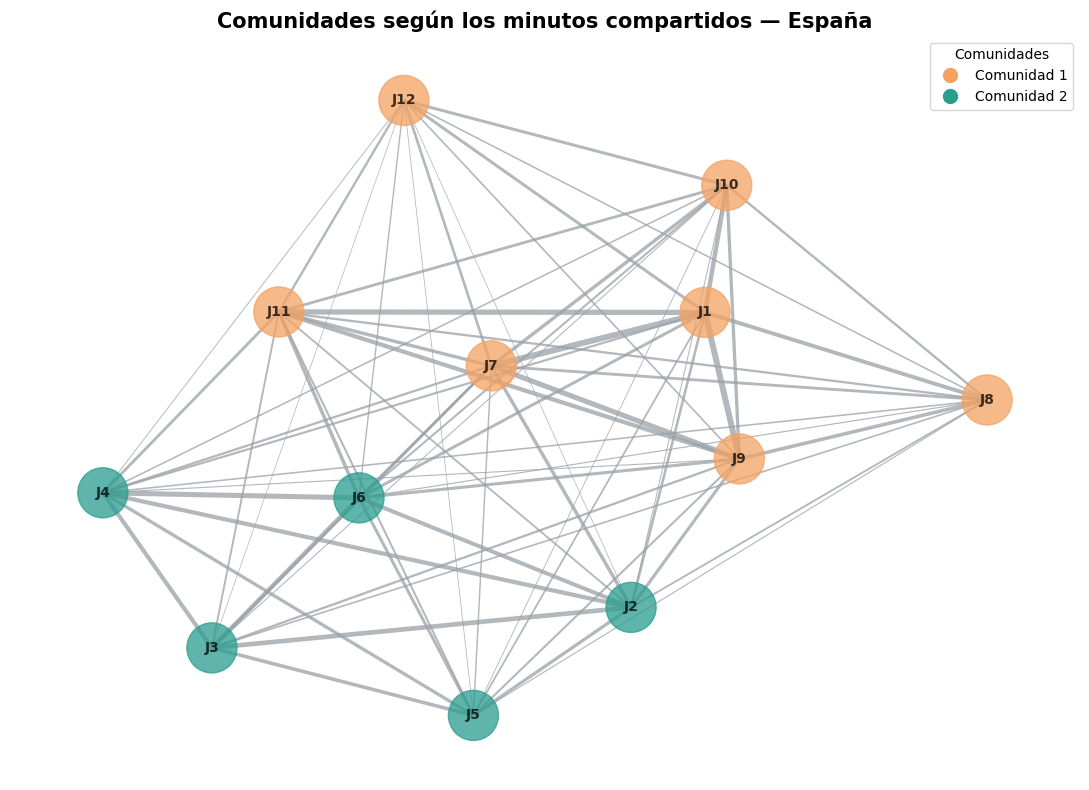

In [105]:
#hago la figura
plt.figure(figsize=(11, 8))

# Dibujo la red utilizando las posiciones dela red general
nx.draw_networkx(
    G_general,
    pos=pos,
    node_color=colores_nodos,
    node_size=1300,
    edge_color="#9AA0A6",
    width=grosores,
    alpha=0.75,
    font_size=10,
    font_weight="bold"
)

#pongo la leyenda
leyenda = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label=f"Comunidad {numero}",
        markerfacecolor=color,
        markersize=12
    )
    for numero, color in colores_comunidades.items()
]

plt.legend(
    handles=leyenda,
    title="Comunidades",
    loc="best"
)

plt.title(
    "Comunidades según los minutos compartidos — España",
    fontsize=15,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()

# Guardo la grafica de comunidades
ruta_grafica_comunidades = os.path.join(
    CARPETA_REDES,
    "red_comunidades.png"
)

plt.savefig(
    ruta_grafica_comunidades,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

la cercania espacial de los dos nodos ayuda a visualizar sus conexiones -> pero no es una distancia física !!! ni una medida exacta dle rendimiento


**la elevada cantidad de enlaces entre ambos grupos confirma que las rotaciones fueron flexibles y que las comunidades no funcionarion como bloques independientes**

In [106]:
# Guardo la tablacomunidades
ruta_tabla_comunidades = os.path.join(
    CARPETA_REDES,
    "comunidades_jugadoras.csv"
)

df_comunidades.to_csv(
    ruta_tabla_comunidades,
    index=False
)

In [107]:
#hago una tabla resumen del analisis
df_resumen_comunidades = pd.DataFrame({
    "Numero_Comunidades": [len(comunidades)],
    "Modularidad": [modularidad]
})


#guuardo el resumen con la modularidad
ruta_resumen_comunidades = os.path.join(
    CARPETA_REDES,
    "resumen_comunidades.csv"
)

df_resumen_comunidades.to_csv(
    ruta_resumen_comunidades,
    index=False
)


In [108]:
#miro si estan bien las rutas de guardado
print("Gráfica guardada en:", ruta_grafica_comunidades)
print("Tabla guardada en:", ruta_tabla_comunidades)
print("Resumen guardado en:", ruta_resumen_comunidades)

Gráfica guardada en: /content/drive/MyDrive/TFG_UGR/Redes_UGR/red_comunidades.png
Tabla guardada en: /content/drive/MyDrive/TFG_UGR/Redes_UGR/comunidades_jugadoras.csv
Resumen guardado en: /content/drive/MyDrive/TFG_UGR/Redes_UGR/resumen_comunidades.csv


**ULTIMO BLOQUEEE! ----> ENTROPIA**

se aplicará la entropía de Shanon al estudio de rotaciones del equipo, siguiendo la propuesta de LIneup Entropy de Shea y Baker

primero se calcula la entropia individual de cada jugador a partir de la distribucion de sus minutos compartidos con los compañeros

luego se relaciona con las centralidades obtenidas antes y se calcula la entropia del equipo según la distribución de min entre los quintetos usados



La **entropía de Shannon** se define como:

**H=-sum_i p_i \log_2(p_i)**

donde (p_i) representa la proporción de minutos correspondiente a cada compañera o quinteto.

**PREPARAR LOS MINUTOS COMPARTIDOS X JUGADORA**

tengo que reorganizar df_parejas red para que cada pareja esté en los 2 sentidos:

j1-j2 tb cuente como conexión de j2-j1

conexiones 1 me va a coger cada pareja en el sentido original de j1 a j2 .

cambio los nombres de las columnas para trabajar con jugadora ,compañera y minutos compartiso

In [109]:
#hago conexiones desde Jugadora_1 hacia Jugadora_2
conexiones_1 = (
    df_parejas_red[
        ["Jugadora_1", "Jugadora_2", "Min"]
    ]
    .rename(
        columns={
            "Jugadora_1": "Jugadora",
            "Jugadora_2": "Companera",
            "Min": "Minutos_Compartidos"
        }
    )
)

conexiones 2 -> la misma informacion pero en sentido contrario

de j2 a j1

In [110]:
#mismas conexiones en el sentido contrario
conexiones_2 = (
    df_parejas_red[
        ["Jugadora_2", "Jugadora_1", "Min"]
    ]
    .rename(
        columns={
            "Jugadora_2": "Jugadora",
            "Jugadora_1": "Companera",
            "Min": "Minutos_Compartidos"
        }
    )
)


con pd.concat uno las 2 tablas de conexiones, la original y la invertida (tengo ambas parejas en los dos sentidos)

ignore_index true me hace un indice nuevo para todas ls filas que me salgan

In [111]:
# Uno las conexiones de los dos sentidos
df_conexiones_jugadoras = pd.concat(
    [conexiones_1, conexiones_2],
    ignore_index=True
)

sort values ordena primero x jugadora y luego por compañero

key usa numero jugador para que el orden sea j1,j2,j3... y reset index vuelve a crear un indice desde 0

In [112]:
#ordeno la tabla x jugador y compañero
df_conexiones_jugadoras = (
    df_conexiones_jugadoras
    .sort_values(
        ["Jugadora", "Companera"],
        key=lambda columna: columna.map(numero_jugadora)
    )
    .reset_index(drop=True)
)

In [113]:
print(
    "numero de conexiones dirigidas:",
    len(df_conexiones_jugadoras)
)

display(
    df_conexiones_jugadoras.head(15)
)

numero de conexiones dirigidas: 130


,Jugadora,Companera,Minutos_Compartidos
0,J1,J2,40.3
1,J1,J4,32.9
2,J1,J5,25.7
3,J1,J6,46.9
4,J1,J7,102.6
5,J1,J8,65.2
6,J1,J9,103.5
7,J1,J10,75.5
8,J1,J11,90.0
9,J1,J12,48.4


da 130 conexiones, yo tenia 65 parejas unicas -> 65 x 2 = 130

**ENTROPIA INDIVIDUAL LE**

**CONVERTIR MINUTOS EN PROPORCIONES**

Tengo que empezar calculando la proporcion de los minutos de cada jugadora comparte con cada compañero

-> los minutos de cada conexion se dividen entre la suma de todos los min-pareja de ese jugador

pij= mij / sum mij, las proporciones de todos los jugadores deben de sumar 1

groupby jugadora me reune todas las conexiones de cada jugadora
y transform sum calcula la suma ->  y luego transform me da el total en todas las filas de misma jugadora ojo!!

In [114]:
#total de min-pareja de cada jugadora
df_conexiones_jugadoras["Total_Minutos_Pareja"] = (
    df_conexiones_jugadoras
    .groupby("Jugadora")["Minutos_Compartidos"]
    .transform("sum")
)

divido los minutos de cada pareja entre el total de minutos -pareja del jugador

In [115]:
#proporciOn de minutos de cada conexion
df_conexiones_jugadoras["Proporcion"] = (
    df_conexiones_jugadoras["Minutos_Compartidos"]
    / df_conexiones_jugadoras["Total_Minutos_Pareja"]
)


con groupby vuelvo a agrupar x jugadora y sumo las proporciones de las divisiones anteriores

In [116]:
#compruebo q las proporciones suman 1 para cada jugadora
comprobacion_proporciones = (
    df_conexiones_jugadoras
    .groupby("Jugadora")["Proporcion"]
    .sum()
    .reset_index()
)

display(
    comprobacion_proporciones.round(6)
)

,Jugadora,Proporcion
0,J1,1.0
1,J10,1.0
2,J11,1.0
3,J12,1.0
4,J2,1.0
5,J3,1.0
6,J4,1.0
7,J5,1.0
8,J6,1.0
9,J7,1.0


genial!!! queda validado , las sumatorias dan 1

las 12 jugadoras estan bien construidas: cada jugadora reparte el 100% de sus minutos - pareja entre sus compañeras

**CONTRIBUCION DE CADA COMPAÑERO**

uso la formula -plog_2 (p) a cada pareja

con np.log2() -> hago el logaritmo base 2 igual que en el libro

In [117]:
df_conexiones_jugadoras["Contribucion_Entropia"] = (
    -df_conexiones_jugadoras["Proporcion"]
    * np.log2(df_conexiones_jugadoras["Proporcion"])
)

ahora con groupby cojo todas las conexiones de cada jugador

con agg () sumo sus contribuciones para obtener la entropia LE

con munique cuento con cuántas compañeros diferentes  jugó

ordeno los jugadores de j1 a j12

In [118]:
#sumo las contribuciones d cada jugadora
df_entropia_individual = (
    df_conexiones_jugadoras
    .groupby("Jugadora", as_index=False)
    .agg(
        Entropia_LE=("Contribucion_Entropia", "sum"),
        Numero_Companeras=("Companera", "nunique"),
        Minutos_Pareja=("Minutos_Compartidos", "sum")
    )
    .sort_values(
        "Jugadora",
        key=lambda columna: columna.map(numero_jugadora)
    )
    .reset_index(drop=True)
)

display(df_entropia_individual.round(3))

,Jugadora,Entropia_LE,Numero_Companeras,Minutos_Pareja
0,J1,3.186,10,631.0
1,J2,3.232,11,488.8
2,J3,3.045,10,428.2
3,J4,3.203,11,460.3
4,J5,3.206,11,349.0
5,J6,3.308,11,533.9
6,J7,3.334,11,580.2
7,J8,3.287,11,363.0
8,J9,3.280,11,578.0
9,J10,3.213,11,400.9


como entropia LE ronda por 3 y pico -> compartieron sus minutos de forma bastante repartida entre todas ls compañeros

el numero de compañeras ha sido de 10-11 por lo tanto han compartido casi todos con todos

**importante!!!** los minutos parejas es la suma d elos minutos compartidos con todos los compañeros **ojo!!!!! no son sus minutos reales en pista!!!**

**lo siguiente -> normalizar la entropia para ver si lo veo más claro**

j1 y j3 jugaron con 10 compañeras y el resto con 11 compañeros

mayor entropia : j11 con 3,351 y j7 con 3,334 -> sus min estuvieron mas repartidos entre sus compañeros

menor entropia : j3 con 3,045 y j12 con 3,121  su tiempo estuvo algo más concentrado con determinados compañeros


no quiere decir que unos rindan mejor que otros!!! solo mide la diversidad y el reparto de sus compañeros en pista

**NORMALIZAR ENTRE 0 Y 1**

max me da el maximo numero de compañeros,, que es 11  y np.log2 me hace la entropia maxima teorica del equipo

luego tengo que dividir cada entropia LE entre ese maximo -> si me sale muy proximo a 1 -> + uniformemente repartió el jugador sus min entre todos los posibles compañeros

In [119]:
#hago la entropia max posible
numero_maximo_companeras = (
    df_entropia_individual["Numero_Companeras"].max()
)

entropia_maxima = np.log2(numero_maximo_companeras)

In [120]:
#normalizo la entropia: 0 y 1
df_entropia_individual["Entropia_Normalizada"] = (
    df_entropia_individual["Entropia_LE"]
    / entropia_maxima
)

display(
    df_entropia_individual[
        [
            "Jugadora",
            "Entropia_LE",
            "Entropia_Normalizada",
            "Numero_Companeras"
        ]
    ].round(3)
)

,Jugadora,Entropia_LE,Entropia_Normalizada,Numero_Companeras
0,J1,3.186,0.921,10
1,J2,3.232,0.934,11
2,J3,3.045,0.880,10
3,J4,3.203,0.926,11
4,J5,3.206,0.927,11
5,J6,3.308,0.956,11
6,J7,3.334,0.964,11
7,J8,3.287,0.950,11
8,J9,3.280,0.948,11
9,J10,3.213,0.929,11


se ve una entropia alta -> no significa mayor rendimiento!!! sino mayor diversidad en los comapñeros con los que se jugó

j11 con 0,969 tiene un reparto + uniforme de minutos

j7 con 0,964 y j6 con 0,956 son los siguientes

j3 con 0,880 tiene un reparto mas concentrado y solo 10 jugadores

**UNIR ENTROPIA , CENTRALIDADES Y COMUNIDADES EN UNA SOLA TABLA**

**OBJETIVO:**  estudiar si los jugadores con mayor peso o rendimiento en la red presentan también una mayor diversidad de compañeros.

*La entropía y la centralidad no son medidas opuestas ni equivalentes:*

**centralidad** , mide cuánto peso o rendimiento acumulan las conexiones

**entropia** mide cómo se distribuye ese peso

**una centralidad favorable acompañada de entropía alta** se puede observar en combinaciones + variadas

**una centralidad favorable con entropia baja** puede estar especialmente influida por unas pocas compañeras

**una entropia alta** no demuestra que la jugadora provoque el rendimiento

**una entropía baja** tampoco invalida su centralidad, pero obliga a interpretarla con más cuidado.

merge me une  df comunidades con los resultados de entropia utilizando la columna jugadora

how left -> me deja todas las jugadoras de la 1º tabla

In [121]:
#junto la entropia con las comunidades y las centralidades
df_entropia_red = df_comunidades.merge(
    df_entropia_individual[
        [
            "Jugadora",
            "Entropia_LE",
            "Entropia_Normalizada",
            "Numero_Companeras"
        ]
    ],
    on="Jugadora",
    how="left"
)

columnas entropia red indica que variables quiero consevar y en que orden tienen que estar

sort values organiza las jugadoras desde la j1 hasta j12

reset index -> reinicia el indice

In [122]:
#escojo y ordeno las columnas
columnas_entropia_red = [
    "Jugadora",
    "Comunidad",
    "Minutos_por_Partido",
    "Centralidad_Ofensiva",
    "Centralidad_Defensiva",
    "Balance",
    "Entropia_LE",
    "Entropia_Normalizada",
    "Numero_Companeras"
]

df_entropia_red = (
    df_entropia_red[columnas_entropia_red]
    .sort_values(
        "Jugadora",
        key=lambda columna: columna.map(numero_jugadora)
    )
    .reset_index(drop=True)
)

display(df_entropia_red.round(3))

,Jugadora,Comunidad,Minutos_por_Partido,Centralidad_Ofensiva,Centralidad_Defensiva,Balance,Entropia_LE,Entropia_Normalizada,Numero_Companeras
0,J1,1,22.5,1.965,1.040,0.925,3.186,0.921,10
1,J2,2,17.5,2.300,1.007,1.293,3.232,0.934,11
2,J3,2,15.3,2.205,0.831,1.374,3.045,0.880,10
3,J4,2,16.4,2.285,0.912,1.373,3.203,0.926,11
4,J5,2,12.5,2.074,0.825,1.249,3.206,0.927,11
5,J6,2,19.1,2.105,0.974,1.131,3.308,0.956,11
6,J7,1,20.7,2.027,1.096,0.931,3.334,0.964,11
7,J8,1,13.0,1.895,0.893,1.002,3.287,0.950,11
8,J9,1,20.6,2.014,0.983,1.031,3.280,0.948,11
9,J10,1,14.3,1.996,0.968,1.028,3.213,0.929,11


**comunidades** -> era el grupo habitual dentro de la red

**centralidades / balance** -> influencia ofensiva /defensiva

**entropia** -> variedad con la que cada jugador comparte sus minutos

ejemplo -> j11 combina un balance alto 1,327 con la entropia + alta 0,968

j3 tiene un balance incluso mayor con 1,374 pero una entropia mas baja 0,880

**GRAFICA DE ENTROPIA INDIVIDUAL**

BARRAS -> ENTROPIA NORMALIZADA

COLOR -> CADA COMUNIDAD


In [123]:
from matplotlib.patches import Patch

sort values ordena a los jugadores desde la menor hasta la mayor entropia

el diccionario asigna un color a cada comunidad y map lo aplica a cada jugador

In [124]:
#preparo datos y colores
df_grafica_entropia = (
    df_entropia_red
    .sort_values("Entropia_Normalizada")
)

colores_comunidades = {
    1: "#E07A5F",
    2: "#4C9FAD"
}

colores_barras = (
    df_grafica_entropia["Comunidad"]
    .map(colores_comunidades)
)

hago la grafica

barh -> hace las barras horizontales y usa la entropia normalizada como longitud

bar label me da el valor exacto al final de cada barra (es mejor para verlo)

tengo que añadir la media y la leyenda  : mean calculo la entropia media y axvline la representa en una linea disocntinua -> patch crea los elementos de la leyenda

con set xlim (0, 1.05) -> me hace visible la escala completa de la entropianormalizada

ojo! tight layout es para que los elementos no se corten

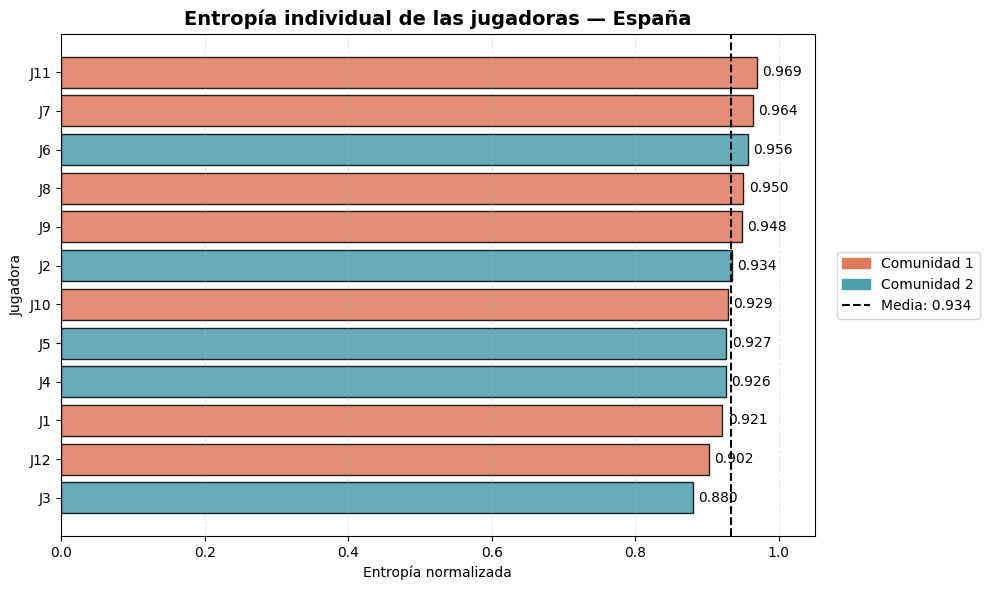

In [125]:
#grafica de barras
fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    df_grafica_entropia["Jugadora"],
    df_grafica_entropia["Entropia_Normalizada"],
    color=colores_barras,
    edgecolor="black",
    alpha=0.85
)

ax.bar_label(
    barras,
    fmt="%.3f",
    padding=4
)

#incluyo  media  y leyenda
media_entropia = df_entropia_red["Entropia_Normalizada"].mean()

ax.axvline(
    media_entropia,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Media: {media_entropia:.3f}"
)

leyenda_comunidades = [
    Patch(color="#E07A5F", label="Comunidad 1"),
    Patch(color="#4C9FAD", label="Comunidad 2")
]
#mejor poner la leyenda no se solape con la grafica
ax.legend(
    handles=leyenda_comunidades + [ax.lines[0]],
    loc="center left" , bbox_to_anchor = (1.02 , 0.5)
)


#personalizo
ax.set_xlim(0, 1.05)
ax.set_xlabel("Entropía normalizada")
ax.set_ylabel("Jugadora")
ax.set_title(
    "Entropía individual de las jugadoras — España",
    fontsize=14,
    fontweight="bold"
)

ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


la media del equipo es 0,934

j11, j7 , j6 , j8 y j9 estan x encima de la media

j2 coincide con la media

j3 presenta mayor entropia seguido de j12

**rojo comunidad 1 : j1  , j7, j8, j9 , j10 , j11 y j12**

**azu comunidad 2 : j2, j3 , j4,j5 y j6**

j11 y j7 tienen entropia alta y son de la comunidad 1

j6 tiene entropia alta pero está en comunidad 2

**COMPARAR : ENTROPIA VS CENTRALIDAD Y COMUNIDADES**

creo una lista con las variables que quiero comparar , dejo fuera las columnas jugadora y comunidad

In [126]:
variables_comparacion = [
    "Entropia_Normalizada",
    "Minutos_por_Partido",
    "Centralidad_Ofensiva",
    "Centralidad_Defensiva",
    "Balance"
]

con corr() calculo como varian conjuntamente las metricas spearmean  (comparo posiciones / rangos .

Resultado estará entre -1 y +1 -> si es positivo indica que ambas tienden a aumentar juntas, negativo que una aumenta cuando la otra disminuye

proxima a 0 -> no existe una relacion clara

**LA MATRIZ DE CORRELACIONES DE SPEARMAN**

Cada casilla me compara 2 valores entre -1 y +1

como es simétrica basta con leer la mitad de la tabla (la diagonal cada variable se compara consigo misma)

In [127]:
#correlaciones de Spearman
matriz_correlaciones = (
    df_entropia_red[variables_comparacion]
    .corr(method="spearman")
)

display(matriz_correlaciones.round(3))

,Entropia_Normalizada,Minutos_por_Partido,Centralidad_Ofensiva,Centralidad_Defensiva,Balance
Entropia_Normalizada,1.000,0.399,0.042,0.231,-0.091
Minutos_por_Partido,0.399,1.000,0.168,0.706,-0.210
Centralidad_Ofensiva,0.042,0.168,1.000,-0.140,0.832
Centralidad_Defensiva,0.231,0.706,-0.140,1.000,-0.601
Balance,-0.091,-0.210,0.832,-0.601,1.000


**entropia - minutos** -> 0,399  es una relacion positiva moderada -> los que jugaron + minutos tienden ligeramente a repartirlos + compañeros , pero no es una relacion fuerte


**entropia -centralidad ofensiva** -> 0,042 . Casi no existe relacion -> tener minutos variados no implica una mayor influencia ofensiva


**entropia -centralidad defensiva ->** 0,231  es relaicon positiva debil . importante!!! esta centralidad representa pc/min -> un valor alto significa recibir más puntos -> no defender mejor


**balance - entropia ->** -0,091  es casi nula . -> la diveresidad de compañeros no parece asociarse con un balance mejor /peor

**si miro el balance (la difereencia entre la producion ofensiva y la defensiva de cada jugadora dentro de la red)** :

**BALANCE = CENTRALIDAD OFENSIVA - CENTRALIDAD DEFENSIVA**

BALANCE POSITIVO Y ALTO -> DURANTE SUS CONEXIONES SE ANOTA MAS PUNTOS X MIN DE LOS QUE RECIBEN

BALANCE PROXIMO A 0 -> ATAQUE Y DEFENSA ESTAN EQUILIBRADOS

BALANCE NEGATIVO , SE RECIBEN MAS PUNTO X MIN DE LOS QUE SE ANOTAN

**centralidad ofensiva - balance**: 0,832 -> cuanto mayor es la produccion ofensiva, normalmente mayor es el balance

**centralidad defensiva - balance :** -0,601 -> recibir mas puntos por minuto tiende a reducir balance


**conclusion :** en esta muestra, la entropia describe la variedad de compañeras, pero no parece estar clararmente relacionado con el rendimiento ofensivo/debensivo/global .

al tener 12 compañeros se debe interpretar como un resultado descriptivo

**COMPARAR COMUNIDADES**

con groupy separo las jugadoras segun los dos grupos de comunidades

agg cuenta cuenateas hay en cada comunidad  y calcula la media de la entropia / los minutos /las centralidades y el balance

In [128]:
resumen_comunidades_entropia = (
    df_entropia_red
    .groupby("Comunidad", as_index=False)
    .agg(
        Numero_Jugadoras=("Jugadora", "count"),
        Entropia_Media=("Entropia_Normalizada", "mean"),
        Minutos_Medios=("Minutos_por_Partido", "mean"),
        Centralidad_Ofensiva_Media=("Centralidad_Ofensiva", "mean"),
        Centralidad_Defensiva_Media=("Centralidad_Defensiva", "mean"),
        Balance_Medio=("Balance", "mean")
    )
)

display(resumen_comunidades_entropia.round(3))

,Comunidad,Numero_Jugadoras,Entropia_Media,Minutos_Medios,Centralidad_Ofensiva_Media,Centralidad_Defensiva_Media,Balance_Medio
0,1,7,0.940,17.029,2.005,0.974,1.031
1,2,5,0.925,16.160,2.194,0.910,1.284


**COMUNIDAD  1 **

formada por 7 jugadores

tiene una entropia media de 0,940 ligeramente superior

juega una media de 17,029 minutos

su centralidad ofensiva media es de 2,005 y recibe 0,974 puntos por minuto

con balance medio de 1,031

**COMUNIDAD 2**

lo forman 5 jugadores

su entropia media es 0,925 algo menor

juega una media de 16,160 minutos

tiene mayor centralidad ofensiva 2,194 y tiene menor centralidad defensiva 0,910 , lo que aqui es mejor porque representa menos puntos recibidos

obtiene un balance medio superior 1,284


conclusion -> la 1 muestra una variedad ligeramente mayor de compañeros y algo más tiempo medio en pista , sin embargo la 2 presenta mejores valores medios de ataque /defensa /balance.

la diferencia de entropia es pequeña , 0,015 , y solo tengo 12 jugadores -> comparacion descriptiva , no es suficiente para afirmar que una comunidadsea estadisticamente mejor que otra

**GRAFICA ENTROPIA FRENTE BALANCE**

entropia frente balance , diferenciando las comunidades

con for separo los datos de cada comunidad -> represento los jugadores como un punto -> con interrow recorro la tabla jugador x jugador  y luego escribo el codigo junto al punto

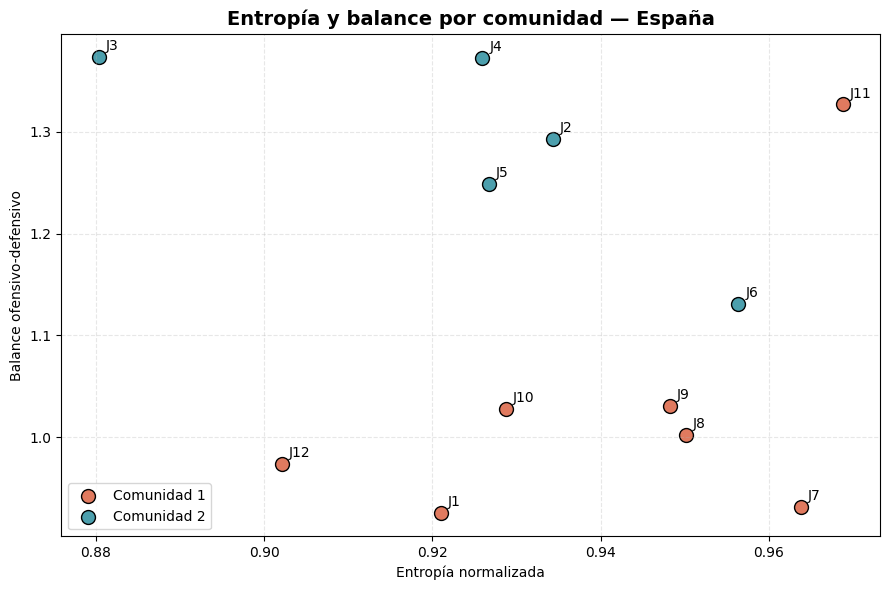

In [129]:
#hago grafica de entropiia y balance
fig, ax = plt.subplots(figsize=(9, 6))

#for me separa los datos de cada comunidad
for comunidad, color in colores_comunidades.items():
    datos_comunidad = df_entropia_red[
        df_entropia_red["Comunidad"] == comunidad
    ]
#scatter represeneta cada jugador como un punto
    ax.scatter(
        datos_comunidad["Entropia_Normalizada"],
        datos_comunidad["Balance"],
        color=color,
        s=100,
        edgecolor="black",
        label=f"Comunidad {comunidad}"
    )

#pongo el nombre de cada jugador
#interrow recorre la tabla jugador x jugador
for _, fila in df_entropia_red.iterrows():
    #annotate escribe el codigo junto al pto
    ax.annotate(
        fila["Jugadora"],
        (
            fila["Entropia_Normalizada"],
            fila["Balance"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )



# Personalizo
ax.set_xlabel("Entropía normalizada")
ax.set_ylabel("Balance ofensivo-defensivo")
ax.set_title(
    "Entropía y balance por comunidad — España",
    fontsize=14,
    fontweight="bold"
)

ax.grid(linestyle="--", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

veo mejor los perfiles individuales y la separacion entre las comunidades!!!!

**COMUNIDAD 2 :** concentra en general los balances mas altos, j3 y j4 tienen balances excelentes aunque sus entropias sean diferentes  -> un balance alto no exige necesariamente jugar de forma muy repartida

**COMUNIDAD 1 :** tiene los balances mas bajos , pero ojo! j11 que destaca porque combina la entropia mas alta con un balance muy elevado

j7 es lo contrario a j11 tiene una entropia muy alta pero tiene un balance muy bajo porque ha jugado de forma variada  pero esa variedad no implica un mejor rendimiento

tampoco veo que los puntos formen una linea ascendente ni descendete -> la correlacion era cercana a 0 -> -0,091


**conclusion :** la entropia me permite distinguir cómo se distribuyen las conexiones con cada jugador  pero no me determina por si sola su rendimiento. He visto perefiles diferentes como j11  (alta diversidad y alto balance ) pero j3 , menor entropia  pero alto balance

**ENTROPIA DE LOS QUINTETOS - TLE**

el equipo concentra sus minutos en unos pocos quintetos o distribuye el tiempo entre muchas combinaciones diferentes?

Se mide con **Team Lineup Entropy , TLE**

**TLE alta** , los minutos están distribuidos entre muchos quintetos

**TLE baja** el equipo concentra el tiempo en un grupo pequeño de quintetos

**TLE da el grado de variedad de las alineaciones, pero no indica directamente una mayor o menor calidad deportiva.**

1º preparo las proporciones de minutos de cada quinteto , con groupby reuno todos las apariciones del mismo quinteto -> sum () acumulo los minutos

In [130]:
#agrupo los minuts d cada quinteto
df_entropia_quintetos = (
    df_quintetos_reales
    .groupby("Quinteto_J", as_index=False)["Minutos"]
    .sum()
)

primero sumo todos los minutos registrados -> luego divido los minutos de cada quinteto entre ese total . obtento qj que es la proporcion del tiempo del equipo correspondiente a cada quinteto

In [131]:
#calculo el total de minutos y la proporcin de cada quinteto
total_minutos_quintetos = (
    df_entropia_quintetos["Minutos"].sum()
)

df_entropia_quintetos["Proporcion"] = (
    df_entropia_quintetos["Minutos"]
    / total_minutos_quintetos
)

con len tiene que devolver lso 88 quintetos diferentes y la suma de las proporciones debe ser 1

solo muestro los 10 quintetos con mas minutos para comprobar como se distribuye inicialmente su tempo

In [132]:
print(
    "numero de quintetos:",
    len(df_entropia_quintetos)
)

print(
    "Suma de las proporcions:",
    round(df_entropia_quintetos["Proporcion"].sum(), 6)
)

display(
    df_entropia_quintetos
    .sort_values("Minutos", ascending=False)
    .head(10)
    .round(4)
)


numero de quintetos: 88
Suma de las proporcions: 1.0


,Quinteto_J,Minutos,Proporcion
49,J2 - J3 - J4 - J5 - J6,27.4667,0.0981
40,J1 - J7 - J8 - J10 - J12,12.8667,0.0460
46,J1 - J7 - J9 - J10 - J12,10.2000,0.0364
52,J2 - J3 - J4 - J6 - J7,9.8833,0.0353
86,J4 - J6 - J10 - J11 - J12,9.6167,0.0343
47,J1 - J8 - J9 - J10 - J11,9.1667,0.0327
42,J1 - J7 - J8 - J9 - J10,9.1333,0.0326
71,J3 - J4 - J5 - J6 - J11,8.2500,0.0295
61,J2 - J3 - J6 - J7 - J9,8.1833,0.0292
45,J1 - J7 - J9 - J10 - J11,7.9833,0.0285


fijarme en que la suma de las proporicones suma 1

el quinteot mas usado representa aproximadamente el 9,81 % del tiempo total

**ENTROPIA GLOBAL DEL EQUIPO**

TLE = - sum from{k} q_k log_2 ( q_k )

aplico a cada quinteto la misma formula de shanon  

los quintetos con una proporcion muy pequeña aportaran poco -> pero una distribucion mas repartida subirá la entropia total

In [133]:
#contribuciOn de cada quinteto
df_entropia_quintetos["Contribucion_TLE"] = (
    -df_entropia_quintetos["Proporcion"]
    * np.log2(df_entropia_quintetos["Proporcion"])
)


como he usado 88 quintetos diferentes, la entropía máxima teórica de esta muestra

**TL E_max= log_2 ( 88 )**

la entropia normalizada:  **TL E_norm = TLE over { log_2 (88) }**

**cercana a 1**, los minutos estarían repartidos de forma muy parecida entre los 88 quintetos

**cercana a 0** , casi todo el tiempo estaría concentrado en unos pocos

la TLE normalizada depende de los quintetos observados en los  7 partidos . No representaría necesariamente toda la estructura de rotación de una temporada (liga endesa , euroleague tienen mas partidos que un europeo /mundial)

con sum () se reunen todas ls contribuciones de los 88 quintetos para calcular la TLE -> LUEGO divido entre log2 (88)  -> seria el maximo si todos hubiesen jugado exactamente el mismo tiempo

In [134]:
#Calculo y normalizo la entropia del equipo
entropia_equipo_TLE = (
    df_entropia_quintetos["Contribucion_TLE"].sum()
)

entropia_maxima_TLE = np.log2(
    len(df_entropia_quintetos)
)

entropia_equipo_normalizada = (
    entropia_equipo_TLE / entropia_maxima_TLE
)

ojo!!! 2**TLE transforma la entropia en un resultado muy intuitivo : el num efectivo de quintetos!!  -> indicara a cuántos quintetos igualmente utilizados equivaldria realmente la distribuccion

In [135]:
#hayo el numero efectivo d quintetos
quintetos_efectivos = 2 ** entropia_equipo_TLE

print("Entropía del equipo (TLE):", round(entropia_equipo_TLE, 3))
print("Entropía normalizada:", round(entropia_equipo_normalizada, 3))
print("Número efectivo de quintetos:", round(quintetos_efectivos, 2))

Entropía del equipo (TLE): 5.804
Entropía normalizada: 0.899
Número efectivo de quintetos: 55.88


**TLE** de 5,804 es la entropia total de las distribuciión de minutos entre los quintetos

**entropia normalizada** es del 89,9% del maximo posible -> España usó una rotacion de quintetos bastante variada

**numero efectivo =55,88**  , aunque se usaron 88 quintetos diferentes -> su distribucion de minutos equivale aprox a usar 56 quintetos por igual

**quiere decir** no es que no se usaran los 88, sino que algunos tuvieron muy pocos minutos y al tener en cuenta el reparto -> se reduce a unos 56

**GRAFICA DE CONCENTRACION DE LOS QUINTETOS**

se colocan primero los quintetos mas usados -> y luego se van acumulando sus proporciones para saber que pare del tiempo total reunen los primeros 1,2...quintetos

In [136]:
#Ordeno ls quintetos y calculo su proporcioon acumulada
df_concentracion_quintetos = (
    df_entropia_quintetos
    #sort values coloca primero lso quintetos mas usados
    .sort_values("Proporcion", ascending=False)
    .reset_index(drop=True)
)

df_concentracion_quintetos["Orden"] = (
    np.arange(1, len(df_concentracion_quintetos) + 1)
)
#cumsum va acumulando sus proporciones para saber que
#parte del tiempo total reunen los primeros quintetos
df_concentracion_quintetos["Proporcion_Acumulada"] = (
    df_concentracion_quintetos["Proporcion"].cumsum()
)


**numero de quintetos necesarios para alcanzar el 50 % de los minutos**

numero de quintetos necesarios para alcanzar **el 80%  y 90 %**

con np.searchsorted localizo la 1º posicion en la que la proporcion acumulada alcanza cada % -> se suma 1 xk las posiciones internas comienzan en cero

**si TLE es alta y acomapaña a muchos quintetos con pocos minutos indicará una rotación muy fragmentada**

Una TLE moderada, pero con el 50% del tiempo concentrado en pocos quintetos , nos dirá la existencia de un nucleo principal y numerosas combinaciones secundarias.

In [137]:
# Calculo cuantos quintetos acumulan el 50 %,80 %,90 % dl tiempo
niveles = [0.50, 0.80, 0.90]

quintetos_por_nivel = {
    #np.searchsorted localiza la 1º posicion en la proporcion
    nivel: np.searchsorted(
        df_concentracion_quintetos["Proporcion_Acumulada"],
        nivel
        #sumo 1 xk las posiciones internas comienzan en 0
    ) + 1
    for nivel in niveles
}

for nivel, numero in quintetos_por_nivel.items():
    print(
        f"Quintetos necesarios para alcanzar el "
        f"{nivel * 100:.0f}% del tiempo: {numero}"
    )

Quintetos necesarios para alcanzar el 50% del tiempo: 15
Quintetos necesarios para alcanzar el 80% del tiempo: 40
Quintetos necesarios para alcanzar el 90% del tiempo: 55


los 15 quintetos mas usados reunen el 50% de los minutos

se necesitan 40 quintetos para alcanzar el 80 %

se necesitan 55 quintetos para llegar al 90%

por lo que-> los quintetos del 56 al 88 -> los 33 restantes solo reunen aprox el 10% final

**los ptos rojos** señalan cuantos son necesario para reunir el 50 % , 80% y 90% de todos los minutos

**las lineas horizontales** sn para ver mejor los 3 niveles estudiados

**una curva que suba muy rapido** -> concentracion en pocos quintetos

**una subida gradual** seria una rotacion mas repartida

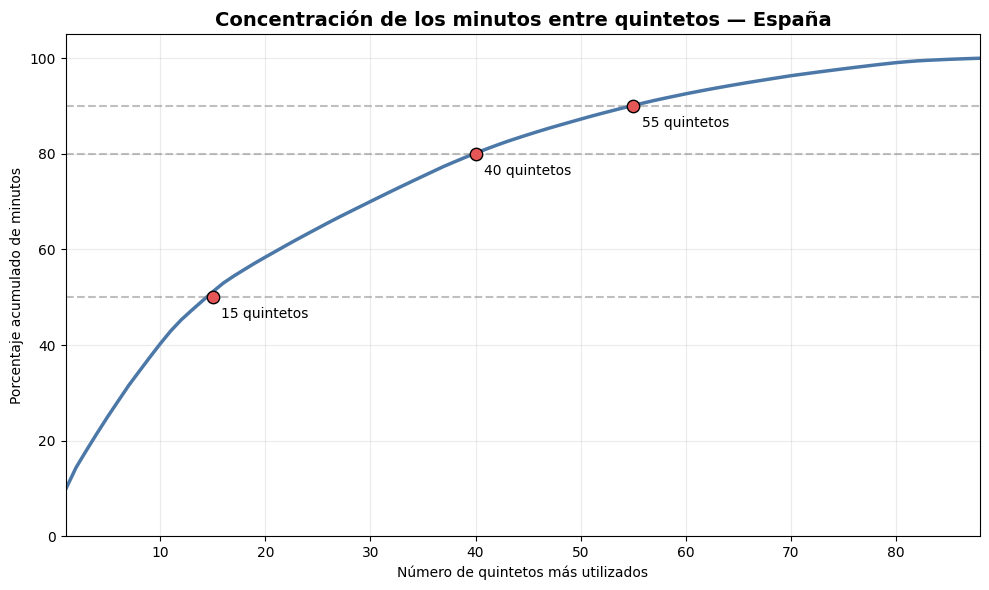

In [138]:
#curva concentracion
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    df_concentracion_quintetos["Orden"],
    df_concentracion_quintetos["Proporcion_Acumulada"] * 100,
    color="#4C78A8",
    linewidth=2.5
)

for nivel, numero in quintetos_por_nivel.items():
    porcentaje = nivel * 100

    ax.scatter(
        numero,
        porcentaje,
        s=80,
        color="#E45756",
        edgecolor="black",
        zorder=3
    )

    ax.annotate(
        f"{numero} quintetos",
        (numero, porcentaje),
        xytext=(6, -15),
        textcoords="offset points"
    )


# Personalizo
ax.axhline(50, color="gray", linestyle="--", alpha=0.5)
ax.axhline(80, color="gray", linestyle="--", alpha=0.5)
ax.axhline(90, color="gray", linestyle="--", alpha=0.5)

ax.set_xlabel("Número de quintetos más utilizados")
ax.set_ylabel("Porcentaje acumulado de minutos")
ax.set_title(
    "Concentración de los minutos entre quintetos — España",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlim(1, len(df_concentracion_quintetos))
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

la curva sube con bastente rapidez al principio xk algunos quintetos acumulan mas tiempo pero despues lo hace de una forma mas gradual

**no existe una rotacion totalmente uniforme** -> tampoco esta concentrada en unas pocas combinaciones

**-> España usó una gran diversidad de alineaciones, la mitad del tiempo se concentró en 15 quintetos principales, mientras que fue necesario incluir 55 combinaciones para explicar el 90% de los minutos**

me falta guardar las tablas !!!

In [139]:
#tabla con los resultados generales del equipo
df_resumen_entropia_equipo = pd.DataFrame({
    "Quintetos_Observados": [len(df_entropia_quintetos)],
    "Entropia_TLE": [entropia_equipo_TLE],
    "Entropia_Normalizada": [entropia_equipo_normalizada],
    "Quintetos_Efectivos": [quintetos_efectivos],
    "Quintetos_50_Porciento": [quintetos_por_nivel[0.50]],
    "Quintetos_80_Porciento": [quintetos_por_nivel[0.80]],
    "Quintetos_90_Porciento": [quintetos_por_nivel[0.90]]
})

display(df_resumen_entropia_equipo.round(3))

,Quintetos_Observados,Entropia_TLE,Entropia_Normalizada,Quintetos_Efectivos,Quintetos_50_Porciento,Quintetos_80_Porciento,Quintetos_90_Porciento
0,88,5.804,0.899,55.88,15,40,55


los 88 quintetos observados , mi TLE de 5,804 , entropia de 0,889 ,equivale a unos 55,88 quintetos efectivos usados de manera uniforme , 15,40 y 55 quintetos para alcanzar el 50% ,  80% y 90% de de los minutos

la TLE de 5,804 mide la diversidad en el uso de los quintetos , su valor normalizado de 0,899 indica una arotacion muy variada aunque no totalmente uniforme

In [140]:
ruta_entropia_jugadoras = os.path.join(
    CARPETA_REDES,
    "entropia_jugadoras.csv"
)

ruta_entropia_quintetos = os.path.join(
    CARPETA_REDES,
    "entropia_quintetos.csv"
)

ruta_resumen_entropia = os.path.join(
    CARPETA_REDES,
    "resumen_entropia_equipo.csv"
)


In [141]:
#guardo las tablas en archivoscsv
df_entropia_red.to_csv(
    ruta_entropia_jugadoras,
    index=False
)

df_concentracion_quintetos.to_csv(
    ruta_entropia_quintetos,
    index=False
)

df_resumen_entropia_equipo.to_csv(
    ruta_resumen_entropia,
    index=False
)

print("Tablas de entropía guardadas correctamente")

Tablas de entropía guardadas correctamente


**RESUMEN:**

los jugadores presentan una entropia normalizad alta -> indica que comparten sus minustos con compañeros variados

no se observa una relacion clara entre la entropia y el rendimiento ofensivo  / defensivo / o el balance -> una mayor divesidad no implica necesariamente un mejor rendimiento

la comunidad 1 muestra una entropia media ligeramente superior , pero la comunidad 2 obtiene un mejor balance ofensivo-defensivo

he usado 88 quintetos diferentes -> con un TLE de 5,804  y una entropia normalizada de 0,899 -> ROTACION MUY DIVERSA

EL num efectivo de quintetos es de 55,88 -> aunque se vieron 88 -> su reparto de minutos equivale aprox al uso uniforme de 56 quintetos

solo 15 quintetos concentran el 50% de los minutos, mientras que se necesitan 55 para alcanzar el 90% de los minutos  -> existen combinaciones principales  pero tambien una rotacion muy rapartida

En conjunto , la entropia permite medir la diversidad y flexibilidad de las rotaciones pero debe interpretarse junto con las metricas de rendimiento -> porque no indica por si sola qué jugadores o quintetos funcionan mejor /peor

**limitaciones:**

solo se analizan 7 partidos

las decisiones tácticas dependen del rival y del contexto

lesiones, faltas , sanciones ….

los 88 quintetos incluyen combinaciones utilizadas durante tiempos muy breves

una entropia alta no significa necesariamente un buen rendimiento

una entropia baja no implica una mala gestión de rotación

las centralidades siguen siendo métricas descriptivas de conexiones